# 09: 16QAM e o cenário do VPI

Este notebook vai do 16QAM até a comparação com o VPI, no cenário 400ZR de 4 canais DP-16QAM do grupo, e segue tentando reproduzir o VPI o mais perto possível. O notebook 08 terminou com BPSK e QPSK em uma e duas polarizações, com dois lasers, fibra e o DSP com os símbolos conhecidos. Aqui:

- 16QAM, com o pulso de raiz de cosseno levantado e o filtro casado
- duas polarizações e o piso de SNR do transmissor do VPI
- fibra, primeiro com o DSP com os símbolos conhecidos e depois com o DSP cego, como o do VPI
- quatro canais: o cenário do VPI
- comparação com o VPI em BER e SER, em todos os conjuntos de dados do grupo
- por que o simcopy reproduz o VPI nas potências do meio e não nas bordas
- as hipóteses para as bordas, uma por seção

Os outros formatos, o ADC, a MI e a GMI e o código corretor de erros ficam no notebook 10.

## 16QAM

Cada símbolo leva 4 bits. Os dois primeiros escolhem o nível em fase e os dois últimos o nível em quadratura, com o mesmo código de Gray nos dois eixos: 00 → −3, 01 → −1, 11 → +1, 10 → +3. É a tabela do `QAM_dem` do professor. Os níveis são divididos por 3, para ficarem entre −1 e 1.

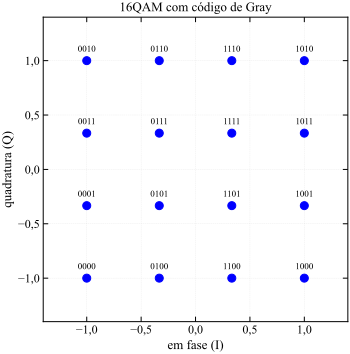

pares de vizinhos: 24 | bits diferentes em cada par: {1}
potência média dos símbolos: 1.1111111111111112


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from simcopy.plotting import apply_style, density_map
apply_style()          # estilo das figuras: guia de figuras do TCC (src/simcopy/plotting.py)

from simcopy.kernels.mapping import constellation, demap, map_bits

points = constellation("16QAM")            # na ordem do valor inteiro dos 4 bits

fig, ax = plt.subplots(1, 1, figsize=(5.5, 5.5))
ax.plot(points.real, points.imag, "o", ms=8)
for value, point in enumerate(points):
    ax.annotate(f"{value:04b}", (point.real, point.imag), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(xlabel="em fase (I)", ylabel="quadratura (Q)", title="16QAM com código de Gray", xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal")
ax.grid(True, alpha=0.3)
plt.show()

# vizinhos a distância mínima diferem em um bit só
neighbors = [(i, j) for i in range(16) for j in range(i) if np.isclose(abs(points[i] - points[j]), 2 / 3)]
print("pares de vizinhos:", len(neighbors), "| bits diferentes em cada par:", {bin(i ^ j).count("1") for i, j in neighbors})
print("potência média dos símbolos:", np.mean(np.abs(points) ** 2))

## Raiz de cosseno levantado e filtro casado

No notebook 08 o transmissor usava o cosseno levantado inteiro. O VPI divide o filtro em dois: a raiz do cosseno levantado no transmissor (`NyquistResponse = squareRootRaisedCosine`) e a mesma raiz no receptor, o filtro casado. O produto dos dois é o cosseno levantado. Com isso o sinal só vale o símbolo depois do filtro casado, que também é o filtro que deixa passar menos ruído.

no centro dos símbolos, sinal menos símbolo (máximo):
   saída do transmissor:   0.32004293790542243
   depois do filtro casado: 1.6165091241761062e-15
maior valor de I(t) na saída do transmissor: 1.879016515362911


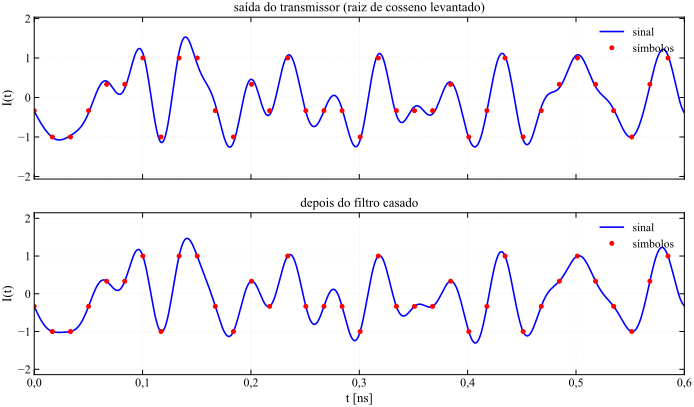

In [2]:
from simcopy.kernels.pulse_shaping import raised_cosine_response, root_raised_cosine_response, shape_pulses

n_symbols = 2048
sps = 16
Rs = 59.84e9              # taxa de símbolos do cenário do VPI
fs = Rs * sps
rolloff = 0.18

rng = np.random.default_rng(1)
symbols = map_bits(rng.integers(0, 2, 4 * n_symbols), "16QAM")
freq = np.fft.fftfreq(n_symbols * sps, 1 / fs)
root = root_raised_cosine_response(freq, Rs, rolloff)

transmitted = shape_pulses(symbols, sps, root)                  # saída do transmissor
matched = np.fft.ifft(np.fft.fft(transmitted) * root)           # depois do filtro casado
centers = np.arange(n_symbols) * sps
time = np.arange(n_symbols * sps) / fs

print("no centro dos símbolos, sinal menos símbolo (máximo):")
print("   saída do transmissor:  ", np.abs(transmitted[centers] - symbols).max())
print("   depois do filtro casado:", np.abs(matched[centers] - symbols).max())
print("maior valor de I(t) na saída do transmissor:", np.abs(transmitted.real).max())

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(time * 1e9, transmitted.real, label="sinal")
ax[0].plot(time[centers] * 1e9, symbols.real, "o", ms=4, label="símbolos")
ax[0].set(ylabel="I(t)", title="saída do transmissor (raiz de cosseno levantado)")
ax[1].plot(time * 1e9, matched.real, label="sinal")
ax[1].plot(time[centers] * 1e9, symbols.real, "o", ms=4, label="símbolos")
ax[1].set(xlabel="t [ns]", ylabel="I(t)", title="depois do filtro casado", xlim=(0, 0.6))
for a in ax:
    a.legend(loc="upper right")
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Na saída do transmissor o sinal não passa pelos símbolos: a diferença chega a 0,32 no centro dos símbolos. Depois do filtro casado ela é de 2e-15. O pico de I(t) é 1,88 vezes o nível externo, um pouco menos que os 2,1 do cosseno levantado inteiro do notebook 08.

## Dupla polarização, um canal, sem fibra

O exemplo `examples/coerente_dp16qam.yaml` tem um canal DP-16QAM a 59,84 GBd, ligado direto ao receptor, com os defeitos de transmissor do arquivo do VPI: 5° de desbalanço de fase no modulador IQ, 0,75 ps de skew entre I e Q, banda S21 de 40 GHz e extinção de 30 dB em cada MZM. O oscilador local é outro laser, a 500 MHz do sinal, e os dois lasers têm 500 kHz de largura de linha.

No transmissor, o laser é dividido meio a meio entre X e Y, e cada metade passa pelo seu modulador IQ. No receptor, o sinal é separado em X e Y, o oscilador local também é dividido, e cada polarização tem a sua híbrida e os seus quatro fotodetectores.

Com `rx.dsp` na configuração, o receptor ganha dois blocos e a medida muda:
- `rx.cd`: compensação de dispersão (não faz nada aqui, porque não há fibra)
- `rx.filter`: filtro casado
- a medida acha o instante dos símbolos e o desvio de frequência, a matriz de polarização, a fase da portadora (média móvel de 21 símbolos) e um equalizador de 7 coeficientes, tudo com os símbolos conhecidos

O instante e o desvio de frequência saem juntos, do produto de cada amostra pelo conjugado da amostra um símbolo antes. Esse produto não depende da polarização nem da fase dos lasers, e um desvio de frequência $\Delta f$ vira nele uma rotação constante de $2\pi\,\Delta f\,T$.

  ch0.tx.bits        BitSource
  ch0.tx.driver      NyquistDriver
  ch0.tx.laser       CWLaser
  ch0.tx.modulator   IQModulator
  ch0.tx.power       PowerControl
  ch0.rx.lo          CWLaser
  ch0.rx.frontend    CoherentFrontEnd
  ch0.rx.cd          DispersionCompensator
  ch0.rx.filter      MatchedFilter
canal 0: BER contada = 6.918e-05 (9/130096) | EVM = 12.94 % (SNR = 17.76 dB) | Q = 3.532 | BER por Q = 2.062e-04 | potencia recebida = -20.00 dBm | instante = 12 amostras | simbolos 61 a 16322 | MI = 3.999, GMI = 3.999 bits/simbolo | SER = 2.767e-04 | por polarizacao: SNR = 17.74, 17.78 dB, BER = 7.687e-05, 6.149e-05
instante = 12 amostras | rotação por símbolo = 0.05279 rad | desvio de frequência = 502.7 MHz (o oscilador local está a 500 MHz)


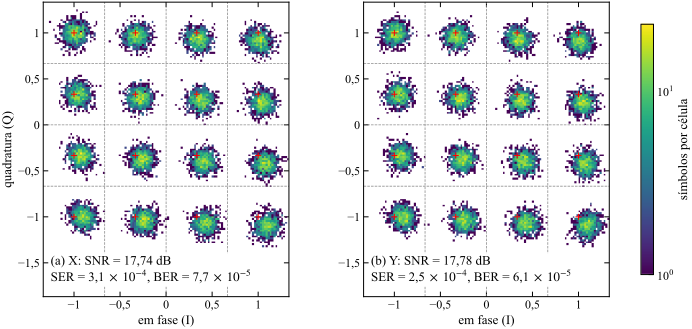

In [3]:
from pathlib import Path

import simcopy
from simcopy.config.io import load
from simcopy.pipelines.runner import run
from simcopy.plotting import plot_constellation

# os exemplos ficam na raiz do repositório, qualquer que seja a pasta em que o notebook roda
repo = Path(simcopy.__file__).parents[2]
examples = repo / "examples"

dp_system, dp_simulation = load(examples / "coerente_dp16qam.yaml")
dp = run(dp_system, dp_simulation)
for stage in dp.stages:
    print(f"  {stage.id:<18} {type(stage.block).__name__}")
print(dp.summary())

# o instante e o desvio de frequência que a medida acha, pelo produto diferencial
from simcopy.kernels.dsp import timing_and_frequency
from simcopy.kernels.mapping import map_bits as map_symbols

sent = np.array([map_symbols(row, "16QAM") for row in dp.output("ch0.tx.bits").data])
delay, rotation = timing_and_frequency(dp.output("ch0.rx.filter").samples, sent, 16)
print(f"instante = {delay} amostras | rotação por símbolo = {rotation:.5f} rad | "
      f"desvio de frequência = {rotation * 59.84e9 / (2 * np.pi) / 1e6:.1f} MHz (o oscilador local está a 500 MHz)")

plot_constellation(dp)
plt.show()

Com −20 dBm no receptor, a SNR é de 17,76 dB (17,74 em X e 17,78 em Y), com 9 erros em 130096 bits. A medida achou o desvio de frequência em 502,7 MHz, para 500 MHz do oscilador local: o que sobra a fase fina acompanha.

Nas duas constelações os pontos não ficam centrados nas cruzes: a grade inteira está deslocada e um pouco inclinada. São dois defeitos do transmissor, que a próxima seção separa.

## De onde vem o piso de SNR

Sem fibra e com potência de sobra, a SNR não passa de ~19 dB. Para ver quem limita, tiramos o ruído do receptor e ligamos um defeito do transmissor por vez.

In [4]:
import dataclasses

channel = dp_system.channels[0]

def with_transmitter(system, mzm=None, iq=None, **tx_fields):
    """O mesmo sistema, com outros campos do MZM, do desbalanço IQ e do transmissor."""
    c = system.channels[0]
    tx = dataclasses.replace(c.tx, mzm=dataclasses.replace(c.tx.mzm, **(mzm or {})),
                             iq=dataclasses.replace(c.tx.iq, **(iq or {})), **tx_fields)
    return dataclasses.replace(system, channels=(dataclasses.replace(c, tx=tx),))

quiet = dataclasses.replace(dp_simulation, shot_noise=False, thermal_noise=False)     # sem ruído do receptor
ideal_mzm = dict(insertion_loss_db=0.0, extinction_ratio_db=np.inf, s21_bandwidth=None)
ideal_iq = dict(phase_imbalance_deg=0.0, skew=0.0)

cases = [
    ("transmissor ideal", ideal_mzm, ideal_iq),
    ("só o desbalanço de fase de 5°", ideal_mzm, {**ideal_iq, "phase_imbalance_deg": 5.0}),
    ("só o skew de 0,75 ps", ideal_mzm, {**ideal_iq, "skew": 0.75e-12}),
    ("só a banda S21 de 40 GHz", {**ideal_mzm, "s21_bandwidth": 40e9}, ideal_iq),
    ("só a extinção de 30 dB", {**ideal_mzm, "extinction_ratio_db": 30.0}, ideal_iq),
    ("todos, como no arquivo do VPI", {}, {}),
]
print("caso                              | SNR [dB] | 1/SNR")
for name, mzm, iq in cases:
    m = run(with_transmitter(dp_system, mzm, iq), quiet).metrics[0]
    print(f"{name:<33} | {m.snr_db:8.2f} | {10 ** (-m.snr_db / 10):.5f}")

caso                              | SNR [dB] | 1/SNR


transmissor ideal                 |    37.39 | 0.00018


só o desbalanço de fase de 5°     |    26.76 | 0.00211


só o skew de 0,75 ps              |    28.51 | 0.00141


só a banda S21 de 40 GHz          |    36.51 | 0.00022


só a extinção de 30 dB            |    21.50 | 0.00708


todos, como no arquivo do VPI     |    20.15 | 0.00966


Com o transmissor ideal a SNR vai a 37,4 dB: o que sobra é o erro do próprio DSP ao seguir o ruído de fase dos lasers. Com todos os defeitos, 20,2 dB.

Quem mais pesa é a extinção de 30 dB dos MZM (21,5 dB sozinha), e não o desbalanço de fase (26,8 dB) nem o skew (28,5 dB). No nulo, um MZM com extinção finita não apaga a portadora: sobra um campo constante, que aparece na constelação como o deslocamento da grade. O desbalanço de fase de 5° aparece como a inclinação da grade. A banda S21 quase não pesa (36,5 dB), porque o equalizador a desfaz.

O equalizador é linear, como o do VPI, e por isso não tira nem o deslocamento nem a inclinação.

## Com fibra: o que cada etapa do DSP faz

Colocamos 125 km de fibra padrão depois do canal, com 0 dBm de lançamento. A fibra tem dispersão, efeito Kerr e PMD, e gira a polarização. Abaixo, a corrente da polarização X do receptor amostrada uma vez por símbolo depois de cada etapa.

canal 0: BER contada = 4.105e-03 (504/122768) | EVM = 17.90 % (SNR = 14.95 dB) | Q = 2.599 | BER por Q = 4.670e-03 | potencia recebida = -25.00 dBm | instante = 12 amostras | simbolos 519 a 15864 | MI = 3.934, GMI = 3.934 bits/simbolo | SER = 1.639e-02 | por polarizacao: SNR = 14.98, 14.91 dB, BER = 4.138e-03, 4.073e-03


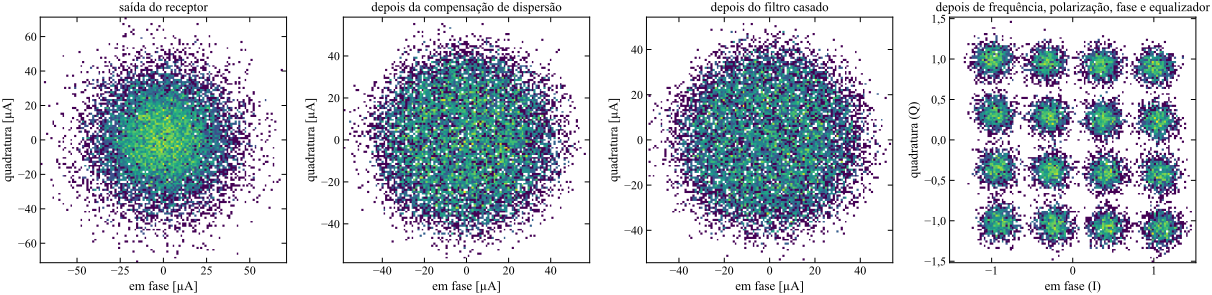

In [5]:
from simcopy.config.system import FiberConfig, LinkConfig, SpanConfig
from simcopy.core.units import dbm_to_w
from simcopy.kernels.demodulation import sample_symbols

fiber_channel = dataclasses.replace(channel, launch_power=dbm_to_w(0.0))
fiber_system = dataclasses.replace(dp_system, channels=(fiber_channel,),
                                   link=LinkConfig(spans=(SpanConfig(FiberConfig(length=125e3)),)))
fiber = run(fiber_system, dp_simulation)
print(fiber.summary())

m = fiber.metrics[0]
stages = (("ch0.rx.frontend", "saída do receptor"),
          ("ch0.rx.cd", "depois da compensação de dispersão"),
          ("ch0.rx.filter", "depois do filtro casado"))
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
for a, (sid, title) in zip(ax, stages):
    samples = sample_symbols(fiber.output(sid).samples[0], 16, m.delay, m.first_symbol, m.last_symbol)
    density_map(a, samples * 1e6)
    a.set(xlabel="em fase [µA]", ylabel="quadratura [µA]", title=title, aspect="equal")
equalized = fiber.symbols[0][0]
density_map(ax[3], equalized)
ax[3].set(xlabel="em fase (I)", ylabel="quadratura (Q)", title="depois de frequência, polarização, fase e equalizador", aspect="equal")
plt.tight_layout()
plt.show()

Algoritmo de Gran Schimidt ortogonalização
Na saída do receptor não há constelação: a dispersão de 125 km espalha cada símbolo por centenas de vizinhos. Depois da compensação de dispersão e do filtro casado os pontos continuam uma nuvem, por três motivos: o desvio de frequência gira a constelação 0,05 rad por símbolo, o ruído de fase dos lasers a gira devagar, e a fibra misturou as duas polarizações. A última etapa desfaz os três com os símbolos conhecidos e os 16 pontos aparecem.

Com 0 dBm de lançamento chegam −25 dBm ao receptor e a SNR é de 14,95 dB. Aqui quem limita é o ruído do receptor.

## DSP cego, etapa por etapa

Com `rx.dsp.mode: blind` o receptor ganha dois estágios. O `rx.adc` amostra a corrente a 2 amostras por símbolo e quantiza. O `rx.dsp` é o receptor cego, que faz, nesta ordem:

- separação das polarizações no espaço de Stokes
- equalizador adaptativo 2×2 de 7 coeficientes, pelo algoritmo de módulo constante
- desvio de frequência, pela raia da quarta potência dos símbolos equalizados
- busca cega de fase, com 64 ângulos, conjunta nas duas polarizações
- ajuste dirigido por decisão: os coeficientes do equalizador são refeitos por mínimos quadrados, com as próprias decisões como alvo

Usamos o canal DP-16QAM das seções anteriores, com os mesmos 125 km de fibra e 0 dBm de lançamento. Abaixo, a polarização X depois de cada etapa. As etapas são as funções de `simcopy.kernels.dsp`, chamadas à mão sobre a saída do ADC.

  ch0.rx.cd          DispersionCompensator
  ch0.rx.filter      MatchedFilter
  ch0.rx.adc         ADC
  ch0.rx.dsp         BlindReceiver
canal 0: BER contada = 4.374e-03 (537/122768) | EVM = 17.86 % (SNR = 14.96 dB) | Q = 2.604 | BER por Q = 4.603e-03 | potencia recebida = -25.00 dBm | instante = 1 amostras | simbolos 519 a 15864 | MI = 3.932, GMI = 3.932 bits/simbolo | SER = 1.746e-02 | por polarizacao: SNR = 15.00, 14.92 dB, BER = 4.415e-03, 4.333e-03


desvio de frequência estimado = 498.6 MHz (o oscilador local está a 500 MHz)


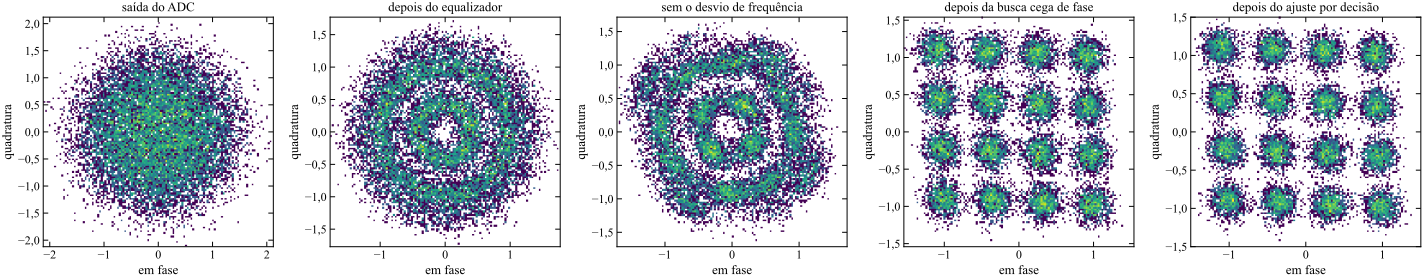

In [6]:
from simcopy.config.simulation import SimulationConfig
from simcopy.kernels import dsp

def with_channel(system, dsp_fields=None, adc_fields=None, **channel_fields):
    """O mesmo sistema, com outros campos do canal, de rx.dsp e de rx.adc."""
    c = system.channels[0]
    rx = dataclasses.replace(c.rx, dsp=dataclasses.replace(c.rx.dsp, **(dsp_fields or {})),
                             adc=dataclasses.replace(c.rx.adc, **(adc_fields or {})))
    return dataclasses.replace(system, channels=(dataclasses.replace(c, rx=rx, **channel_fields),))

blind = dict(mode="blind", phase_window=81)
blind_system = dataclasses.replace(with_channel(dp_system, blind, launch_power=dbm_to_w(0.0)),
                                   link=LinkConfig(spans=(SpanConfig(FiberConfig(length=125e3)),)))
blind_fiber = run(blind_system, dp_simulation)
for stage in blind_fiber.stages[-4:]:
    print(f"  {stage.id:<18} {type(stage.block).__name__}")
print(blind_fiber.summary())

# as etapas do receptor cego, à mão, sobre a saída do ADC
adc = blind_fiber.output("ch0.rx.adc").samples              # (2, 2 amostras por símbolo)
points = constellation("16QAM")
separated = dsp.stokes_polarization_demux(adc)
equalized = dsp.adaptive_equalizer(separated, points)       # módulo constante, 7 coeficientes
recovered, phases, offset = dsp.carrier_recovery(equalized, "16QAM", 64, 81)
final = blind_fiber.output("ch0.rx.dsp").samples            # com o ajuste dirigido por decisão
k = np.arange(equalized.shape[1])
print(f"desvio de frequência estimado = {offset * 59.84e3:.1f} MHz (o oscilador local está a 500 MHz)")

panels = ((adc[0, ::2] / np.sqrt(np.mean(np.abs(adc[0]) ** 2)), "saída do ADC"),
          (equalized[0], "depois do equalizador"),
          (equalized[0] * np.exp(-2j * np.pi * offset * k), "sem o desvio de frequência"),
          (recovered[0], "depois da busca cega de fase"),
          (final[0], "depois do ajuste por decisão"))
fig, ax = plt.subplots(1, 5, figsize=(20, 4.3))
for a, (samples, title) in zip(ax, panels):
    density_map(a, samples)
    a.set(title=title, aspect="equal", xlabel="em fase", ylabel="quadratura")
plt.tight_layout()
plt.show()

Na saída do ADC não há constelação: as duas polarizações estão misturadas pela fibra. Depois do equalizador aparecem os três anéis do 16QAM. O critério do módulo só olha o raio, então a fase fica solta e a constelação gira. Tirando o desvio de frequência (498,6 MHz achados, para 500 MHz) a rotação rápida some e sobra a fase lenta dos lasers, que borra os pontos ao longo dos anéis. A busca cega de fase fixa os 16 pontos, e o ajuste por decisão os aperta um pouco mais.

A SNR do receptor cego neste enlace é de 14,96 dB. Com os símbolos conhecidos, na seção anterior, era de 14,95 dB.

## Cego contra símbolos conhecidos

Sem fibra, variamos a potência na entrada do receptor e comparamos os dois modos do DSP. A diferença entre eles é o que o receptor cego perde por não conhecer os dados.

 P [dBm] | SNR [dB]: conhecidos  cego | BER: conhecidos      cego | saltos de fase
     -30 |                11.03 11.12 |         4.09e-02  4.22e-02 |     0
     -28 |                12.73 12.79 |         1.94e-02  1.94e-02 |     0
     -26 |                14.29 14.33 |         7.19e-03  7.20e-03 |     0
     -24 |                15.68 15.70 |         2.00e-03  2.01e-03 |     0
     -22 |                16.86 16.85 |         4.49e-04  4.80e-04 |     0
     -20 |                17.81 17.78 |         1.08e-04  4.65e-05 |     0
     -18 |                18.54 18.49 |         0.00e+00  0.00e+00 |     0


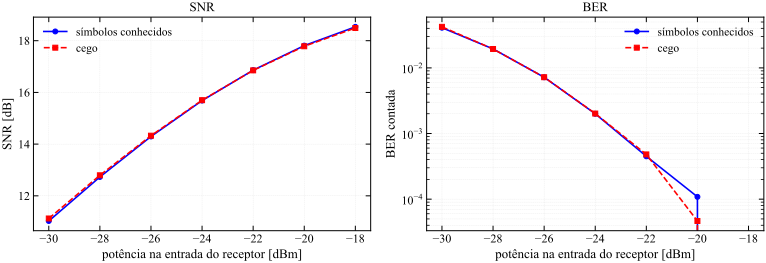

In [7]:
from simcopy.pipelines.runner import with_value

short = SimulationConfig.from_symbols(59.84e9, 16, 2 ** 13, root_seed=0)
powers_dbm = np.arange(-30.0, -17.0, 2.0)

def power_sweep(system, simulation, powers):
    """Métricas do canal 0 para cada potência na entrada do receptor."""
    out = []
    for p in powers:
        s, _ = with_value(system, simulation, "channels[0].launch_power", dbm_to_w(p))
        out.append(run(s, simulation).metrics[0])
    return out

known_sweep = power_sweep(dp_system, short, powers_dbm)
blind_sweep = power_sweep(with_channel(dp_system, blind), short, powers_dbm)

print(" P [dBm] | SNR [dB]: conhecidos  cego | BER: conhecidos      cego | saltos de fase")
for p, a, b in zip(powers_dbm, known_sweep, blind_sweep):
    print(f"{p:8.0f} | {a.snr_db:20.2f} {b.snr_db:5.2f} | {a.ber_counted:16.2e} {b.ber_counted:9.2e} | {b.phase_slips:5d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(powers_dbm, [m.snr_db for m in known_sweep], "o-", label="símbolos conhecidos")
ax[0].plot(powers_dbm, [m.snr_db for m in blind_sweep], "s--", label="cego")
ax[0].set(xlabel="potência na entrada do receptor [dBm]", ylabel="SNR [dB]", title="SNR")
ax[1].semilogy(powers_dbm, [m.ber_counted for m in known_sweep], "o-", label="símbolos conhecidos")
ax[1].semilogy(powers_dbm, [m.ber_counted for m in blind_sweep], "s--", label="cego")
ax[1].set(xlabel="potência na entrada do receptor [dBm]", ylabel="BER contada", title="BER")
for a in ax:
    a.grid(True, which="both", alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

Os dois modos dão a mesma SNR, com diferença de até 0,1 dB, de 11 a 18,5 dB. A BER também coincide onde há erros suficientes para contar (4,1e-2 e 4,2e-2 a −30 dBm, 2,0e-3 e 2,0e-3 a −24 dBm). Não houve salto de fase em nenhum ponto.

O receptor cego não perde nada aqui porque o canal é fixo durante a simulação e o bloco é longo: o ajuste por decisão chega aos mesmos coeficientes que os símbolos conhecidos dariam.

## Saltos de fase

A constelação do 16QAM é igual a si mesma girada de 90°. A busca cega de fase só enxerga a fase a menos desse giro, e com ruído ela pode pular de um giro para outro no meio do bloco. Depois do salto todos os símbolos saem girados, e viram erros.

A janela da busca decide: com poucos símbolos o ruído engana a busca. Comparamos janelas de 21 e de 81 símbolos sobre o mesmo sinal, com pouca potência. A medida conta os saltos comparando o giro de cada bloco de 128 símbolos com os dados.

 P [dBm] | janela | saltos | SER      | SNR [dB]


     -27 |     21 |      0 | 5.18e-02 |  13.57


     -27 |     81 |      0 | 5.03e-02 |  13.52


     -30 |     21 |      8 | 6.52e-01 |  -1.71


     -30 |     81 |      0 | 1.65e-01 |  11.08


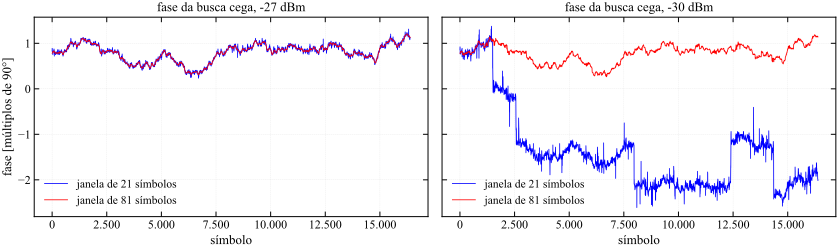

In [8]:
from simcopy.kernels.demodulation import measure_blind

print(" P [dBm] | janela | saltos | SER      | SNR [dB]")
tracks = {}
for p in (-27.0, -30.0):
    s, _ = with_value(with_channel(dp_system, blind), dp_simulation, "channels[0].launch_power", dbm_to_w(p))
    result = run(s, dp_simulation)
    samples = result.output("ch0.rx.adc").samples
    bits = result.output("ch0.tx.bits").data
    guard = result.resolved.channels[0].edge_guard_symbols
    for window in (21, 81):
        symbols, _ = dsp.blind_receiver(samples, "16QAM", window=window)
        m, _ = measure_blind(symbols, bits, "16QAM", guard)
        print(f"{p:8.0f} | {window:6d} | {m.phase_slips:6d} | {m.ser:.2e} | {m.snr_db:6.2f}")
        # fase achada pela busca, na polarização X, sem a rampa do desvio de frequência
        equalized = dsp.adaptive_equalizer(dsp.stokes_polarization_demux(samples), points)
        _, phases, offset = dsp.carrier_recovery(equalized, "16QAM", 64, window)
        tracks[(p, window)] = phases[0] - 2 * np.pi * offset * np.arange(phases.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, p in zip(ax, (-27.0, -30.0)):
    for window in (21, 81):
        a.plot(tracks[(p, window)] / (np.pi / 2), lw=0.8, label=f"janela de {window} símbolos")
    a.set(xlabel="símbolo", title=f"fase da busca cega, {p:.0f} dBm")
    a.grid(True, alpha=0.3)
    a.legend()
ax[0].set(ylabel="fase [múltiplos de 90°]")
plt.tight_layout()
plt.show()

A −27 dBm (13,5 dB de SNR) as duas janelas dão a mesma fase e nenhum salto. A −30 dBm (11 dB) a janela de 21 símbolos salta 8 vezes: a fase pula de um degrau de 90° para outro, a taxa de erro de símbolo vai a 0,65 e a medida inteira se perde. Com 81 símbolos não há salto e a taxa de erro é a esperada para essa SNR (0,17).

A janela maior só funciona porque a fase destes lasers varia devagar: 500 kHz de largura de linha em cada um, a 59,84 GBd. Com lasers piores a janela teria de ser menor, e os saltos voltariam.

## Quatro canais: o cenário do VPI

O arquivo `examples/400zr_4ch_75ghz.yaml` é o cenário do VPI: 4 canais DP-16QAM a 59,84 GBd, espaçados de 75 GHz, mux com filtro gaussiano de ordem 3 (70 GHz, 3 dB de perda), um amplificador booster que define a potência de lançamento (figura de ruído de 5 dB), um trecho de fibra, e o filtro do canal antes do receptor. O canal medido é o de índice 2, como no VPI. O receptor é o cego, com a janela de fase de 43 símbolos, como o do VPI. O transmissor tem os defeitos calibrados nos dados do grupo: o desbalanço de fase de −5° (o `PhaseShift = -90+5` do VPI), o skew de uma amostra da grade (1,044 ps) e a excursão de 0,51 do acionamento.

Os dados do grupo indicam que a potência varrida no VPI (`PowerdBm`) é a soma dos 4 canais. No simcopy a potência do booster é por canal, então 13 dBm no VPI são 13 − 6 dBm por canal. Usamos aqui $2^{13}$ símbolos, para o notebook rodar em cerca de um minuto. O VPI usa $2^{18}$.

potências [dBm]: {'ch2.tx.modulator': -17.85, 'mux': -14.96, 'link.booster': 13.05, 'link.span0.fiber': -11.95, 'ch2.rx.demux': -18.14}
canal 2: BER contada = 1.363e-03 (78/57232) | EVM = 15.82 % (SNR = 16.02 dB) | Q = 2.918 | BER por Q = 1.763e-03 | potencia recebida = -18.14 dBm | instante = 1 amostras | simbolos 519 a 7672 | MI = 3.974, GMI = 3.974 bits/simbolo | SER = 5.451e-03 | por polarizacao: SNR = 16.05, 15.98 dB, BER = 1.503e-03, 1.223e-03


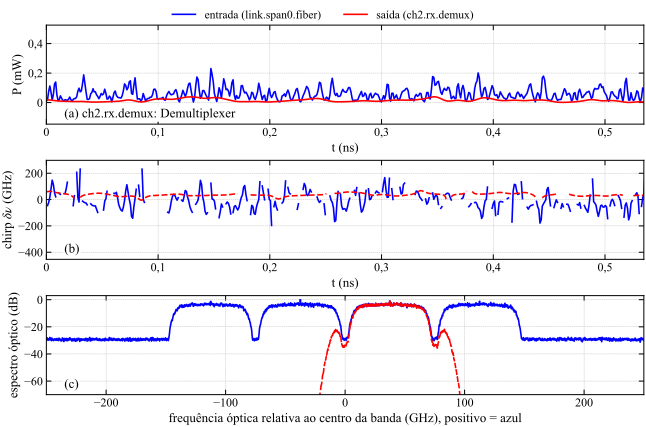

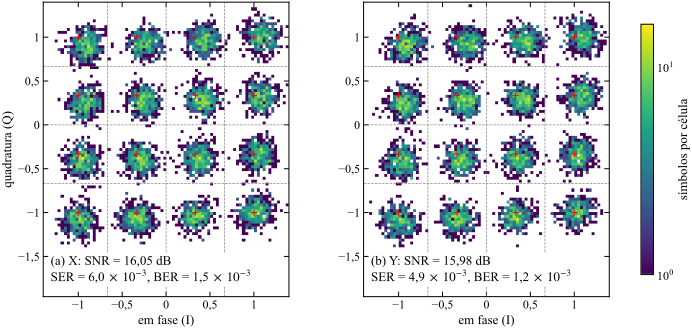

In [9]:
from simcopy.config.simulation import SimulationConfig
from simcopy.plotting import plot_stage

zr_system, zr_simulation = load(examples / "400zr_4ch_75ghz.yaml")
zr_simulation = SimulationConfig.from_symbols(59.84e9, 16, 2 ** 13, root_seed=0)

def with_launch(system, total_dbm, length=125e3):
    """O mesmo sistema, com outra potência total de lançamento e outro comprimento de fibra."""
    span = system.link.spans[0]
    booster = dataclasses.replace(system.link.booster, output_power=dbm_to_w(total_dbm) / system.n_channels)
    link = dataclasses.replace(system.link, booster=booster,
                               spans=(dataclasses.replace(span, fiber=dataclasses.replace(span.fiber, length=length)),))
    return dataclasses.replace(system, link=link)

zr = run(with_launch(zr_system, 13.0), zr_simulation)
print("potências [dBm]:", {sid: round(float(10 * np.log10(zr.output(sid).power) + 30), 2)
                           for sid in ("ch2.tx.modulator", "mux", "link.booster", "link.span0.fiber", "ch2.rx.demux")})
print(zr.summary().splitlines()[2])

plot_stage(zr, "ch2.rx.demux", freq_span=250e9)       # entrada: os 4 canais depois da fibra. Saída: o canal 2
plot_constellation(zr, channel=2)
plt.show()

O booster entrega 13,05 dBm (os 13 dBm pedidos mais o ruído de ASE), a fibra tira 25 dB e o filtro do canal deixa −18,1 dBm do canal 2 no receptor. No espectro, a entrada do filtro tem os 4 canais e a saída só o canal 2, em +37,5 GHz.

Com o receptor cego, a SNR do canal 2 é de 16,02 dB (16,05 em X e 15,98 em Y), a BER é de 1,4e-3 e a SER de 5,5e-3. As constelações têm o deslocamento e a inclinação que os defeitos do transmissor dão, como na seção do piso de SNR.

Neste cenário o filtro casado está desligado (`matched_filter: false`): a cadeia de DSP do VPI não tem um filtro casado separado, e quem filtra é o equalizador de 7 coeficientes.

## Comparação com o VPI em BER e SER

O grupo exportou do VPI as constelações do canal 2 depois do DSP. O script `scripts/catalogo_vpi.py` lê todos os conjuntos da pasta de dados do grupo e conta, em cada ponto, a BER (com o mesmo código de Gray do simcopy), a SER e a SNR. Ele também mede a fração do bloco em que a constelação ficou girada, que é o sinal de que a busca de fase se perdeu. O resultado fica em `reference/vpi/catalogo/catalogo_vpi.json`. Os arquivos do grupo não estão no repositório.

A configuração da simulação só é conhecida em parte dos conjuntos: os de 2026 (125 a 140 km com os 5°, 120 km sem eles) e o de 120 km com os 5° da pasta `400gbps_CH2`. São esses que comparamos aqui com o simcopy, no cenário de `400zr_4ch_75ghz.yaml`, com $2^{14}$ símbolos por ponto. Os pontos do simcopy ficam em `reference/vpi/catalogo/simcopy_400zr.json`.

A métrica principal é a BER, que é a que diz se o enlace funciona. A SER vem junto. Cada painel é um comprimento, com o VPI pontilhado e o simcopy contínuo.

 L [km] | o VPI converge em | BER do simcopy sobre a do VPI | SER do simcopy sobre a do VPI
    120 |  7 a 16 dBm      | 0.88 a 1.07, mediana 0.99  | 0.89 a 1.07, mediana 0.98
    125 |  7 a 17 dBm      | 0.85 a 1.00, mediana 0.96  | 0.85 a 1.00, mediana 0.98
    130 |  8 a 18 dBm      | 0.86 a 0.99, mediana 0.96  | 0.87 a 0.99, mediana 0.96
    135 |  9 a 17 dBm      | 0.87 a 1.01, mediana 0.96  | 0.86 a 1.00, mediana 0.95
    140 | 11 a 17 dBm      | 0.90 a 1.01, mediana 0.97  | 0.90 a 1.00, mediana 0.97


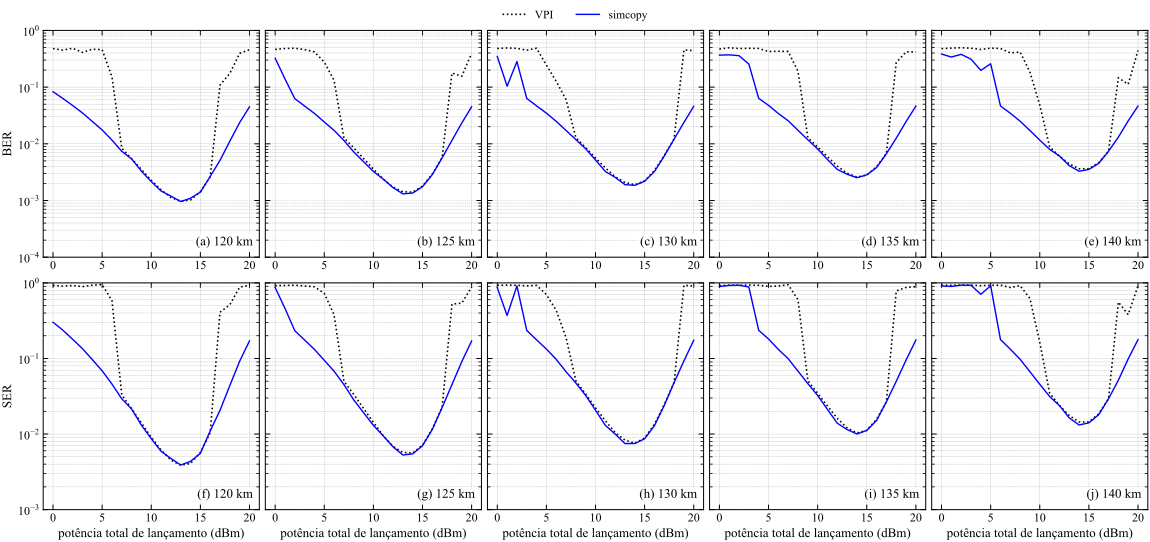

120 km sem os 5°, 7 a 17 dBm: BER do simcopy sobre a do VPI de 0.86 a 1.09 (mediana 0.93), SER de 0.88 a 1.08


In [10]:
import json
from matplotlib.lines import Line2D
from simcopy.plotting import constellation_density, legend_above, panel_label

catalog = repo / "reference" / "vpi" / "catalogo"
vpi_all = json.loads((catalog / "catalogo_vpi.json").read_text(encoding="utf-8"))["points"]
ours = {(p["length_km"], p["power_dbm"]): p
        for p in json.loads((catalog / "simcopy_400zr.json").read_text(encoding="utf-8"))["points"]}

def lost(p):
    """A fase se perdeu: constelação girada em mais de 2 % do bloco, ou BER acima de 0,1."""
    return p.get("rotated_fraction", 0.0) > 0.02 or p["ber"] > 0.1

# conjuntos de configuração conhecida, com os 5°: 120 km da pasta 400gbps_CH2, 125 a 140 km de 2026
known = {}
for p in vpi_all:
    if p["set"] == "2026_4ch" or (p["set"] == "400gbps_CH2" and p["length_km"] == 120):
        known.setdefault(p["length_km"], []).append(p)
lengths = sorted(known)

print(" L [km] | o VPI converge em | BER do simcopy sobre a do VPI | SER do simcopy sobre a do VPI")
for L in lengths:
    good = sorted((p for p in known[L] if not lost(p)), key=lambda p: p["power_dbm"])
    rb = np.array([ours[L, p["power_dbm"]]["ber"] / p["ber"] for p in good])
    rs = np.array([ours[L, p["power_dbm"]]["ser"] / p["ser"] for p in good])
    print(f"   {L:4d} | {good[0]['power_dbm']:2d} a {good[-1]['power_dbm']:2d} dBm      | "
          f"{rb.min():.2f} a {rb.max():.2f}, mediana {np.median(rb):.2f}  | "
          f"{rs.min():.2f} a {rs.max():.2f}, mediana {np.median(rs):.2f}")

cmap = plt.get_cmap("viridis")      # usado nas figuras das hipóteses
fig, ax = plt.subplots(2, len(lengths), figsize=(16, 7.6), layout="constrained", sharey="row")
for k, L in enumerate(lengths):
    v = sorted(known[L], key=lambda p: p["power_dbm"])
    s = sorted((q for (l, _), q in ours.items() if l == L), key=lambda q: q["power_dbm"])
    for row, key in enumerate(("ber", "ser")):
        a = ax[row, k]
        a.semilogy([p["power_dbm"] for p in v], [p[key] for p in v], ":", color="black", lw=1.6)
        a.semilogy([q["power_dbm"] for q in s], [q[key] for q in s], "-", color="blue", lw=1.4)
        a.set(xlabel="potência total de lançamento (dBm)" if row else "",
              ylim=(1e-4, 1) if key == "ber" else (1e-3, 1))
        panel_label(a, f"({'abcdefghij'[row * len(lengths) + k]}) {L} km", corner="lower right")
ax[0, 0].set(ylabel="BER")
ax[1, 0].set(ylabel="SER")
legend_above(fig, [Line2D([], [], ls=":", color="black", lw=1.6), Line2D([], [], color="blue", lw=1.4)],
             ["VPI", "simcopy"], ncol=2)
plt.show()

# 120 km sem os 5° (2026), se a rodada do simcopy existir
sem5_file = catalog / "simcopy_400zr_120km_sem5.json"
if sem5_file.exists():
    sem5 = {p["power_dbm"]: p for p in json.loads(sem5_file.read_text(encoding="utf-8"))["points"]}
    v = sorted((p for p in vpi_all if p["set"] == "2026_4ch_sem5"), key=lambda p: p["power_dbm"])
    rb = np.array([sem5[p["power_dbm"]]["ber"] / p["ber"] for p in v if p["power_dbm"] in sem5])
    rs = np.array([sem5[p["power_dbm"]]["ser"] / p["ser"] for p in v if p["power_dbm"] in sem5])
    print(f"120 km sem os 5°, {v[0]['power_dbm']} a {v[-1]['power_dbm']} dBm: BER do simcopy sobre a do VPI de "
          f"{rb.min():.2f} a {rb.max():.2f} (mediana {np.median(rb):.2f}), SER de {rs.min():.2f} a {rs.max():.2f}")

Onde o VPI converge, a BER do simcopy fica de 0,85 a 1,07 vez a do VPI, com mediana de 0,96 a 0,99 em cada comprimento, e a SER também. Em 120 km sem os 5°, de 0,86 a 1,09, com mediana de 0,93. O simcopy fica quase sempre um pouco abaixo: em potência baixa o VPI tem cerca de 5 % mais ruído do receptor, que ainda não tem explicação (`docs/replicacao_vpi_diario.md`, linha A).

Fora dessa faixa as curvas se separam. O VPI salta para BER de 0,1 a 0,5, e o simcopy continua subindo devagar.

## Por que o meio bate e as bordas não

No meio da faixa quem decide a BER é a física: o ruído e a distorção que o sinal acumula no enlace. O simcopy modela isso bem, e por isso as curvas coincidem.

Nas bordas, quem decide a BER do VPI é o DSP dele perdendo a fase. A busca de fase se engana, e a constelação fica girada em trechos longos do bloco. A BER salta de cerca de 1e-2 para 0,1 a 0,5 em 1 dB de potência: é um precipício, e não uma piora gradual. O simcopy, no mesmo ponto, segue na curva física, que sobe devagar.

A tabela abaixo mostra, para cada conjunto, a SNR do último ponto antes de a fase se perder, em cada borda. Na borda de potência baixa a SNR cai porque o ruído do receptor e a ASE crescem em relação ao sinal. Na de potência alta, porque cresce o ruído não linear da fibra, que é sobretudo ruído de fase.

In [11]:
def edge_snr(points):
    """SNR do último ponto antes de a fase se perder, na borda de potência baixa e na de alta
    (None quando a fase não se perde naquela borda)."""
    pts = sorted(points, key=lambda p: p["power_dbm"])
    good = [p for p in pts if not lost(p)]
    if not good:
        return None, None
    low = good[0]["snr_db"] if any(lost(p) and p["power_dbm"] < good[0]["power_dbm"] for p in pts) else None
    high = good[-1]["snr_db"] if any(lost(p) and p["power_dbm"] > good[-1]["power_dbm"] for p in pts) else None
    return low, high

show = lambda x: "não perde" if x is None else f"{x:5.2f} dB"
print(" conjunto          | L [km] | SNR antes de perder a fase: potência baixa | potência alta")
groups = {}
for p in vpi_all:
    if p["length_km"] is not None:
        groups.setdefault((p["set"], p["length_km"]), []).append(p)
for (name, L), pts in sorted(groups.items()):
    if (name, L) == ("400gbps_CH2", 140):          # igual ao de 2026
        continue
    low, high = edge_snr(pts)
    print(f" VPI {name:<13} | {L:6d} | {show(low):>42} | {show(high):>13}")
for L in lengths:
    low, high = edge_snr([q for (l, _), q in ours.items() if l == L])
    print(f" simcopy           | {L:6d} | {show(low):>42} | {show(high):>13}")

 conjunto          | L [km] | SNR antes de perder a fase: potência baixa | potência alta
 VPI 2021_14GBd    |    150 |                                  não perde |     não perde
 VPI 2021_1ch      |    175 |                                   13.04 dB |      14.32 dB
 VPI 2025_1ch      |    120 |                                   14.02 dB |     não perde
 VPI 2025_4ch      |     80 |                                  não perde |     não perde
 VPI 2025_4ch      |     90 |                                  não perde |     não perde
 VPI 2025_4ch      |    100 |                                  não perde |     não perde
 VPI 2025_4ch      |    110 |                                  não perde |     não perde
 VPI 2025_4ch      |    120 |                                  não perde |     não perde
 VPI 2026_4ch      |    125 |                                   13.54 dB |      14.84 dB
 VPI 2026_4ch      |    130 |                                   13.53 dB |      13.75 dB
 VPI 2026_4ch      | 

Em todos os conjuntos em que a fase se perde, ela se perde quando a SNR cai para 13,0 a 14,2 dB na borda de potência baixa, e para 13,8 a 15,8 dB na de potência alta. O conjunto de 2025 a 120 km tem ainda uma perda isolada a 1 dBm, entre dois pontos em que a fase não se perde: perto do limiar ela pode ou não acontecer, conforme o ruído do bloco.

O simcopy só perde a fase abaixo de 9,8 a 10,8 dB, quase 4 dB depois, e nunca na borda de potência alta. A diferença não está no enlace: a SNR que o simcopy mede nas bordas continua a da física, e a do VPI despenca porque a busca de fase dele se perde antes.

O que acontece dentro do bloco fica claro na fase. Abaixo, a constelação X do VPI em 125 km a 14 dBm (no meio), a 6 dBm e a 18 dBm (nas bordas), e o giro de cada trecho de 128 símbolos em relação aos símbolos transmitidos, módulo 90°. Esta célula lê os arquivos do grupo, e só roda onde a pasta deles existe.

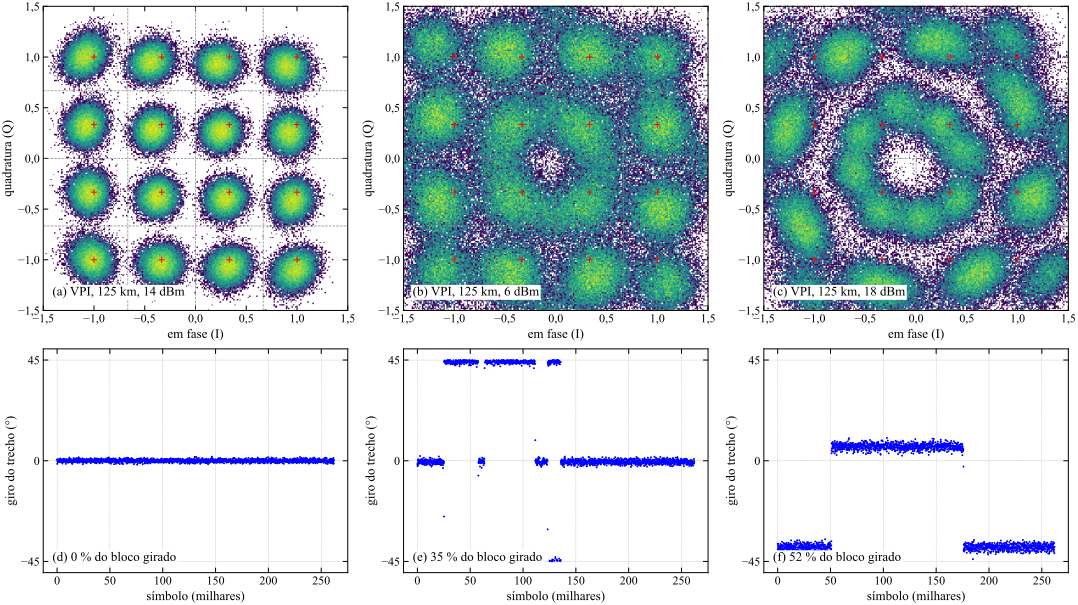

In [12]:
import sys
VPI_DATA = Path(r"C:\Users\bozel\Área de Trabalho\Pesquisa\25-26\dados4canais\extraido")
sys.path.insert(0, str(repo / "scripts"))
import catalogo_vpi as cat

if VPI_DATA.exists():
    base = VPI_DATA / "2026_SIMULATION" / "dados_4_canais"
    ref = cat.to_grid(cat.as_pols(base / "dados_ideais" / "dados_ref_canal2" / "dados_4_canais_ref_X_pol_canal2.csv")[0])
    folder = base / "dados_distorcidos" / "dados_125km" / "dados_125km_canal_2"
    fig, ax = plt.subplots(2, 3, figsize=(15, 8.6), layout="constrained", gridspec_kw={"height_ratios": [1.5, 1]})
    for col, p in enumerate((14, 6, 18)):
        x = cat.as_pols(folder / f"dados_4_canais_canal_2_125km_X_pol_{p}dBm.csv")[0]
        _, lag, conj = cat.best_alignment(cat.decide(x * np.sqrt(10 / np.mean(np.abs(x) ** 2))), ref)
        x = np.conj(x) if conj else x
        a_ref = np.roll(ref, lag)
        y = x / (np.sum(x * np.conj(a_ref)) / np.sum(np.abs(a_ref) ** 2)) / 3     # níveis +-1/3 e +-1
        constellation_density(ax[0, col], y, constellation("16QAM"), 1.5)
        n = (y.size // 128) * 128
        c = np.sum((y[:n] * np.conj(a_ref[:n] / 3)).reshape(-1, 128), axis=1)
        angle = np.degrees(np.angle(c ** 4)) / 4
        ax[1, col].plot(np.arange(angle.size) * 128 / 1e3, angle, ".", ms=2, color="blue")
        ax[1, col].set(xlabel="símbolo (milhares)", ylabel="giro do trecho (°)", ylim=(-50, 50), yticks=[-45, 0, 45])
        panel_label(ax[0, col], f"({'abc'[col]}) VPI, 125 km, {p} dBm")
        panel_label(ax[1, col], f"({'def'[col]}) {100 * np.mean(np.abs(angle) > 22.5):.0f} % do bloco girado")
    plt.show()
else:
    print("pasta dos dados do VPI não encontrada:", VPI_DATA)

A 14 dBm a fase fica no lugar o bloco inteiro. A 6 dBm a busca de fase do VPI pula para 45° em trechos de dezenas de milhares de símbolos (35 % do bloco), e a constelação vira a sobreposição da grade certa com a mesma grade girada de 45°. A 18 dBm o bloco fica dividido entre dois estados afastados de cerca de 45°. O ganho complexo é ajustado no bloco inteiro e fica entre os dois, por isso o trecho do meio aparece a uns 6°.

Em nenhum dos casos a fase anda devagar nem salta 90°, que seriam os modos de falha esperados de uma busca de fase: os estados ficam em múltiplos de 45° e mudam de uma vez. Por isso a primeira hipótese abaixo é a busca de fase.

## Os outros conjuntos do VPI

A pasta de dados do grupo tem mais conjuntos, de 2021 a 2026, quase todos de DP-16QAM. Neles a configuração da simulação não está nos arquivos, então ainda não dá para simular o mesmo cenário no simcopy. A figura mostra a BER de cada um, um painel por conjunto e comprimento. A potência é a que o VPI define em cada conjunto, e em alguns deles não se sabe se é por canal ou total. O de 120 km sem os 5° tem configuração conhecida e aparece também com o simcopy. Os arquivos de 2021 sem comprimento no nome são iguais à referência (BER zero) e ficam de fora.

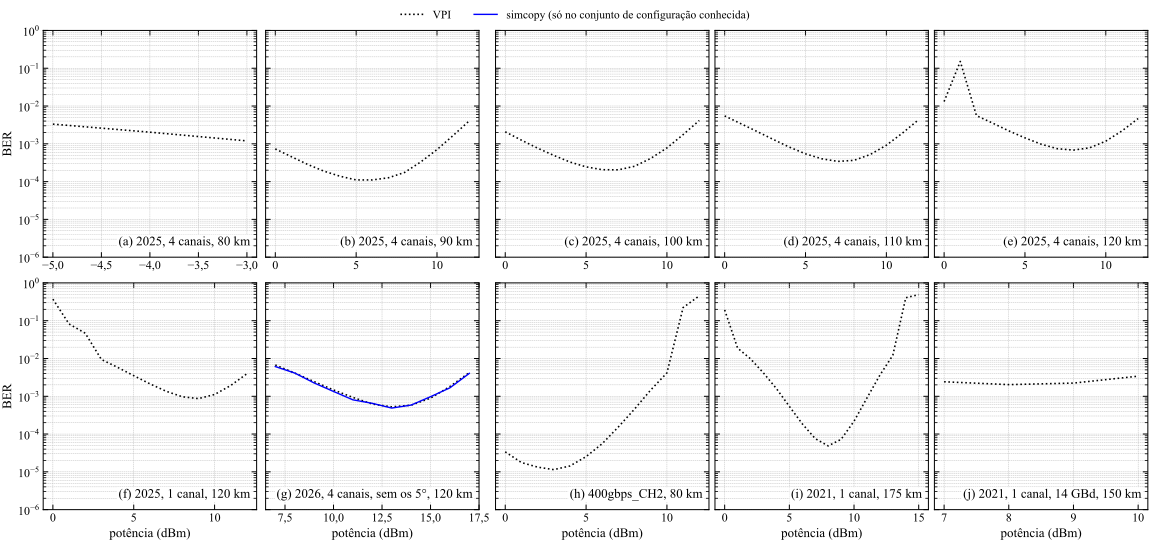

In [13]:
labels = {"2026_4ch_sem5": "2026, 4 canais, sem os 5°", "400gbps_CH2": "400gbps_CH2",
          "2025_4ch": "2025, 4 canais", "2025_1ch": "2025, 1 canal", "2021_1ch": "2021, 1 canal",
          "2021_14GBd": "2021, 1 canal, 14 GBd"}
others = [("2025_4ch", 80), ("2025_4ch", 90), ("2025_4ch", 100), ("2025_4ch", 110), ("2025_4ch", 120),
          ("2025_1ch", 120), ("2026_4ch_sem5", 120), ("400gbps_CH2", 80), ("2021_1ch", 175), ("2021_14GBd", 150)]
sem5_file = catalog / "simcopy_400zr_120km_sem5.json"
sem5 = json.loads(sem5_file.read_text(encoding="utf-8"))["points"] if sem5_file.exists() else []
fig, ax = plt.subplots(2, 5, figsize=(16, 7.6), layout="constrained", sharey=True)
for k, (a, key) in enumerate(zip(ax.flat, others)):
    pts = sorted(groups[key], key=lambda p: p["power_dbm"])
    a.semilogy([p["power_dbm"] for p in pts], [p["ber"] for p in pts], ":", color="black", lw=1.6)
    if key == ("2026_4ch_sem5", 120) and sem5:
        q = sorted(sem5, key=lambda p: p["power_dbm"])
        a.semilogy([p["power_dbm"] for p in q], [p["ber"] for p in q], "-", color="blue", lw=1.4)
    a.set(ylim=(1e-6, 1), xlabel="potência (dBm)" if k >= 5 else "")
    panel_label(a, f"({'abcdefghij'[k]}) {labels[key[0]]}, {key[1]} km", corner="lower right")
ax[0, 0].set(ylabel="BER")
ax[1, 0].set(ylabel="BER")
legend_above(fig, [Line2D([], [], ls=":", color="black", lw=1.6), Line2D([], [], color="blue", lw=1.4)],
             ["VPI", "simcopy (só no conjunto de configuração conhecida)"], ncol=2)
plt.show()

Os conjuntos de 2025 com 4 canais, de 80 a 120 km, têm o ótimo em 6 a 8 dBm, e não em 13 a 14 dBm como os de 2026. O de 2025 com um canal, a 120 km, tem o ótimo em 9 dBm. O de 2021 a 175 km, com um canal, chega a BER de 5e-5 a 8 dBm, melhor que qualquer um de 4 canais a distâncias menores. O de 80 km da pasta `400gbps_CH2` tem o ótimo em 3 dBm. Sem a configuração de cada um, ainda não dá para simular o mesmo cenário no simcopy, e a sexta hipótese testa as variáveis mais prováveis. Nos que perdem a fase, ela se perde nas mesmas SNR da tabela acima.

## Próximos passos: as hipóteses para as bordas

A física do meio já está reproduzida. As bordas pedem um receptor que perca a fase como o do VPI, e cada hipótese abaixo vira uma seção deste notebook, medida em BER e SER em todos os conjuntos de configuração conhecida. A pergunta de cada uma é se o simcopy passa a perder a fase nas mesmas potências que o VPI.

1. Busca de fase como a do VPI: decisão na grade de 256QAM do arquivo dele (`Format = ReadFromFile`) e fase estimada por polarização (`JointEstimation = No`)
2. Equalizador como o do VPI: módulo múltiplo adaptado por gradiente, com 20 passagens (`AlgTDE = MMA`, `Iterations = 20`)
3. Recuperação de frequência às cegas e a ordem da cadeia do VPI: equalizador, separação de polarização, relógio, frequência e fase
4. Recuperação de relógio (`docs/proposta_recuperacao_de_relogio.md`). O VPI tem `ClockRecovery = Off` em todos os blocos, e o bloco `Clock_and_Slice` parece só decimar de 2 para 1 amostra por símbolo: provavelmente não há laço de relógio no VPI para imitar
5. Potência de lançamento: o booster do VPI tem saturação de 10 mW e ganho máximo (`docs/proposta_potencia_de_lancamento.md`)
6. Os conjuntos de configuração desconhecida: testar as variáveis prováveis, como potência por canal ou total, número de canais e comprimento. Por exemplo, se a potência de 2025 for por canal, o ótimo dele em 6 a 8 dBm equivale a 12 a 14 dBm no total, o mesmo dos conjuntos de 2026.

## Hipótese 1: a busca de fase do VPI

O bloco `BlindPhaseSearch` do VPI tem quatro parâmetros que a busca do simcopy não tem: `Format = ReadFromFile` (decisão na grade de `256QAM_constellation.txt`), `JointEstimation = No` (fase estimada por polarização), `FourthPower = Yes` e `FineBlindEstimation = Yes`. Os dois últimos sugerem uma busca em dois estágios: uma fase grossa pela quarta potência dos símbolos, e uma busca fina em torno dela.

O estágio grosso explica os 45°. No 16QAM a média da quarta potência dos pontos é negativa, e a fase grossa sai do ângulo dessa média, com o sinal trocado, dividido por 4. Se o ruído numa janela virar o sinal da média, a fase grossa erra exatamente 45°. A busca fina, restrita a um intervalo em torno da grossa, não consegue corrigir, e a constelação fica girada de 45° até o sinal voltar.

Há uma variante comum na literatura: usar no estágio grosso só os pontos dos anéis de dentro e de fora do 16QAM, cuja quarta potência tem exatamente a fase de 180°. Os pontos do anel do meio entram com outras fases e somam um ruído que vem dos próprios dados, e que vira o sinal da média mesmo sem ruído no canal.

Testamos as variantes sobre os sinais do simcopy na saída do ADC: 51 pontos de 120 a 140 km, com $2^{14}$ símbolos, guardados por `scripts/compara_vpi.py simular --save-signals`. O resto do receptor cego não muda. O script é `scripts/experimentos/busca_fase_vpi.py`, e os resultados ficam em `reference/vpi/hipoteses/h1_busca_de_fase.json`. O placar compara cada variante com o VPI ponto a ponto: em quantos dos 9 pontos em que o VPI perde a fase ela também perde (bordas), em quantos dos 42 em que o VPI converge ela também converge (meio), e a BER onde os dois convergem. A busca fina cobre ±22,5° em torno da grossa, com 64 ângulos e a janela de 43 do VPI.

 variante                                                                       | bordas | meio  | BER sobre a do VPI, no meio
 a busca de hoje: conjunta, decisão no 16QAM                                    |    0/9 | 42/42 | 0.97
 grade de 256QAM, conjunta                                                      |    0/9 | 42/42 | 2.67
 grade de 256QAM, por polarização                                               |    4/9 | 22/42 | 3.19
 dois estágios, conjunta                                                        |    0/9 | 42/42 | 1.06
 dois estágios, por polarização                                                 |    6/9 | 28/42 | 1.24
 dois estágios, por polarização, anéis de dentro e de fora, janela grossa de 43 |    0/9 | 42/42 | 1.12
    o mesmo, janela grossa de 37                                                |    2/9 | 39/42 | 1.12
    o mesmo, janela grossa de 32                                                |    5/9 | 38/42 | 1.12
    o mesmo, janela grossa de 29         

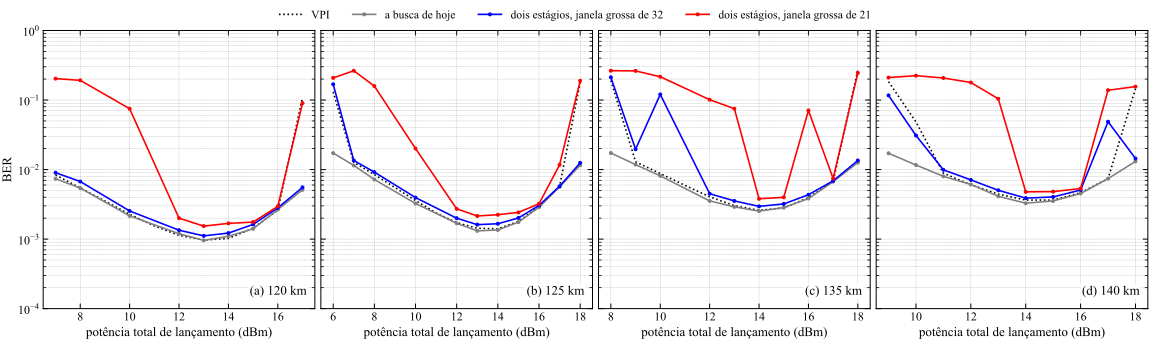

In [14]:
sys.path.insert(0, str(repo / "scripts" / "experimentos"))
from compara_hipotese import score, vpi_points

h1 = json.loads((repo / "reference" / "vpi" / "hipoteses" / "h1_busca_de_fase.json").read_text(encoding="utf-8"))["points"]
vpi_known = vpi_points()
variants = {
    "base": "a busca de hoje: conjunta, decisão no 16QAM",
    "grade256_s4.123": "grade de 256QAM, conjunta",
    "por_polarizacao_grade256_s4.123": "grade de 256QAM, por polarização",
    "quarta_fina_22": "dois estágios, conjunta",
    "por_polarizacao_quarta_fina_22": "dois estágios, por polarização",
    "por_polarizacao_particionada_22": "dois estágios, por polarização, anéis de dentro e de fora, janela grossa de 43",
    "por_polarizacao_particionada_22_grossa37": "   o mesmo, janela grossa de 37",
    "por_polarizacao_particionada_22_grossa32": "   o mesmo, janela grossa de 32",
    "por_polarizacao_particionada_22_grossa29": "   o mesmo, janela grossa de 29",
    "por_polarizacao_particionada_22_grossa25": "   o mesmo, janela grossa de 25",
    "por_polarizacao_particionada_22_grossa21": "   o mesmo, janela grossa de 21",
}
print(f" {'variante':<78} | bordas | meio  | BER sobre a do VPI, no meio")
for key, label in variants.items():
    s = score([r for r in h1 if r["variant"] == key], vpi_known)
    print(f" {label:<78} | {s['edges']:>6} | {s['middle']:>5} | {s['ber_ratio_median']:.2f}")

shown = {"base": ("gray", "a busca de hoje"),
         "por_polarizacao_particionada_22_grossa32": ("blue", "dois estágios, janela grossa de 32"),
         "por_polarizacao_particionada_22_grossa21": ("red", "dois estágios, janela grossa de 21")}
fig, ax = plt.subplots(1, 4, figsize=(16, 4.8), layout="constrained", sharey=True)
for k, (a, L) in enumerate(zip(ax, (120, 125, 135, 140))):
    powers = sorted({r["power_dbm"] for r in h1 if r["length_km"] == L})
    v = sorted((p for p in known[L] if powers[0] <= p["power_dbm"] <= powers[-1]), key=lambda p: p["power_dbm"])
    a.semilogy([p["power_dbm"] for p in v], [p["ber"] for p in v], ":", color="black", lw=1.6)
    for key, (color, _) in shown.items():
        pts = sorted((r for r in h1 if r["variant"] == key and r["length_km"] == L), key=lambda r: r["power_dbm"])
        a.semilogy([r["power_dbm"] for r in pts], [r["ber"] for r in pts], "-", marker=".", ms=6, color=color)
    a.set(xlabel="potência total de lançamento (dBm)", ylim=(1e-4, 1))
    panel_label(a, f"({'abcd'[k]}) {L} km", corner="lower right")
ax[0].set(ylabel="BER")
handles = [(Line2D([], [], ls=":", color="black", lw=1.6), "VPI")]
handles += [(Line2D([], [], color=c, marker=".", ms=6), label) for c, label in shown.values()]
legend_above(fig, [h for h, _ in handles], [t for _, t in handles], ncol=4)
plt.show()

A grade de 256QAM fica descartada: no meio, a BER sobe para 2,7 a 3,2 vezes a do VPI, e o VPI não tem esse custo.

Os dois estágios por polarização, com o estágio grosso só nos anéis de dentro e de fora, reproduzem o modo de falha do VPI: a constelação girada de 45° em trechos longos, com frações giradas e BER perto das do VPI. A janela do estágio grosso decide o limiar:

- com 21 símbolos, a variante perde a fase nos 9 pontos de borda, e na borda de potência alta os números quase coincidem (125 km a 18 dBm: 55 % do bloco girado e BER de 0,19, contra 52 % e 0,18 no VPI). Mas ela também perde a fase em 22 pontos do meio
- com 32 símbolos, ela acerta as 5 bordas de potência baixa e 38 dos 42 pontos do meio, mas não perde a fase em potência alta. No meio a BER fica 12 % acima da do VPI (a busca de hoje fica 3 % abaixo)
- com 43, nunca perde

Os erros no meio ficam colados no limiar (130 km a 8 dBm tem 13,5 dB de SNR no VPI), e lá a falha depende do ruído de cada bloco: o simcopy usa $2^{14}$ símbolos e o VPI $2^{18}$.

A hipótese explica a borda de potência baixa. A de potência alta pede algo mais: no VPI ela aparece com SNR entre 13,8 e 15,8 dB, e na variante com janela de 32 não aparece. A próxima hipótese é o equalizador do VPI, que age antes da busca de fase e pode mudar o que ela recebe em potência alta.

Uma ressalva sobre a leitura dos parâmetros. `FourthPower = Yes`, `FineBlindEstimation = Yes` e `FilterLength = 32` aparecem com os mesmos valores em todos os blocos de DSP do VPI (equalizador, relógio, frequência e busca de fase). Parecem valores padrão do componente genérico `DSP_Lib`, que o bloco da busca de fase pode nem usar. O que o grupo mudou nesse bloco foi `NPreSymbols`, `NbTestAngles` e `Format`. A busca em dois estágios reproduz o modo de falha do VPI, mas continua sendo uma hipótese: só o manual do VPI, ou a rodada pedida ao grupo com a fase estimada exportada, confirma o que ele faz.

Correção, feita na hipótese 4: a fração girada desta seção soma as duas polarizações. Com a fase estimada por polarização, uma polarização alinhada e a outra saltada de 90° somam um vetor a 45°. Medido em cada polarização, o modo de falha destas variantes é o salto de 90°, e não o estado de 45° do VPI. A leitura acima sobre o modo de falha não vale.

## Hipótese 2: o equalizador do VPI

O MIMO do VPI (`AlgTDE = MMA`, `Iterations = 20`, `StepSize = 1e-3`) se adapta por gradiente, símbolo a símbolo, pelo raio dos pontos. O receptor cego do simcopy usa o módulo constante e depois um ajuste por mínimos quadrados com as decisões, em bloco. Um equalizador por gradiente deixa os coeficientes oscilando em torno da solução, e o critério do raio não vê o ruído de fase. As duas coisas podem mudar onde a busca de fase se perde, sobretudo em potência alta.

Combinamos cada equalizador com três buscas de fase: a de hoje e as duas da hipótese 1 (dois estágios por polarização, janela grossa de 32 e de 21). Equalizadores: o de hoje, o critério por raio com 20 passagens e passo de 1e-3 ou 3e-4 (saída com os coeficientes de cada instante, ou com os do fim aplicados ao bloco inteiro), e o critério por raio seguido de 4 passagens por decisão, por gradiente. Script: `scripts/experimentos/equalizador_vpi.py`. Resultados em `reference/vpi/hipoteses/h2_equalizador.json`.

 equalizador                                             | busca de fase     | bordas | meio  | BER sobre a do VPI, no meio
 o de hoje                                               | busca de hoje     |    0/9 | 42/42 | 0.97
 o de hoje                                               | dois estágios, 32 |    5/9 | 38/42 | 1.12
 o de hoje                                               | dois estágios, 21 |    9/9 | 20/42 | 1.38
 por raio, passo 1e-3, coeficientes de cada instante     | busca de hoje     |    0/9 | 42/42 | 1.21
 por raio, passo 1e-3, coeficientes de cada instante     | dois estágios, 32 |    6/9 | 37/42 | 1.41
 por raio, passo 1e-3, coeficientes de cada instante     | dois estágios, 21 |    9/9 | 20/42 | 1.78
 por raio, passo 1e-3, coeficientes do fim               | busca de hoje     |    0/9 | 42/42 | 1.20
 por raio, passo 1e-3, coeficientes do fim               | dois estágios, 32 |    5/9 | 33/42 | 1.40
 por raio, passo 1e-3, coeficientes do fim               | dois está

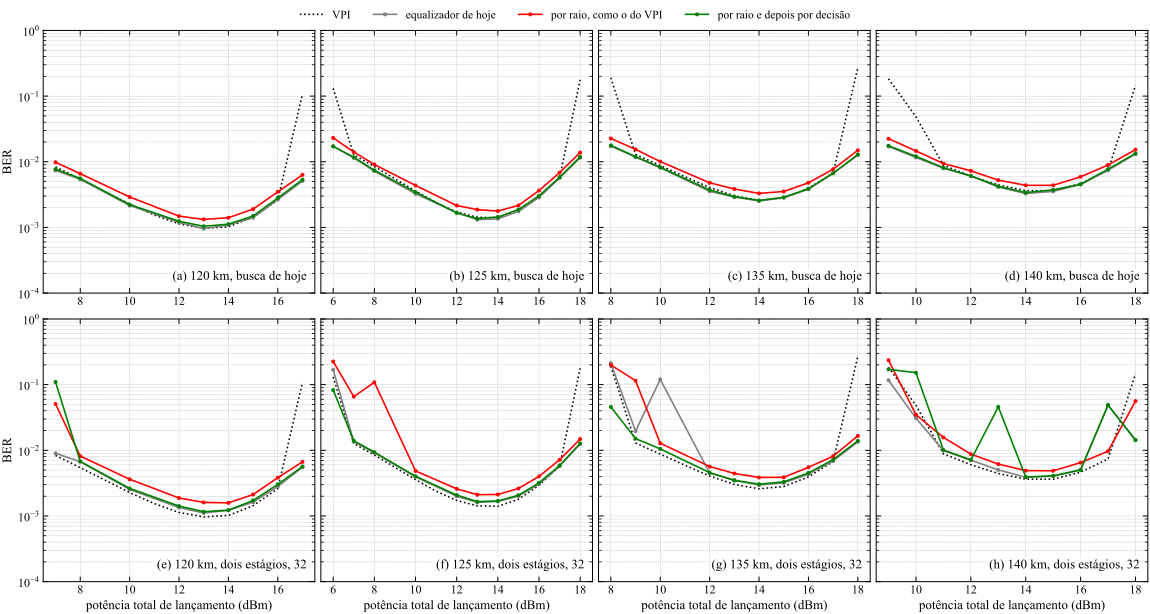

In [15]:
h2 = json.loads((repo / "reference" / "vpi" / "hipoteses" / "h2_equalizador.json").read_text(encoding="utf-8"))["points"]
equalizers = {"simcopy": "o de hoje", "raio_0.001_corrente": "por raio, passo 1e-3, coeficientes de cada instante",
              "raio_0.001_congelada": "por raio, passo 1e-3, coeficientes do fim",
              "raio_0.0003_corrente": "por raio, passo 3e-4, coeficientes de cada instante",
              "raio_lms_corrente": "por raio e depois por decisão (LMS)"}
searches = {"conjunta": "busca de hoje", "dois_estagios_32": "dois estágios, 32", "dois_estagios_21": "dois estágios, 21"}
print(f" {'equalizador':<55} | {'busca de fase':<17} | bordas | meio  | BER sobre a do VPI, no meio")
for eq, eq_label in equalizers.items():
    for se, se_label in searches.items():
        s = score([r for r in h2 if r["variant"] == f"{eq}+{se}"], vpi_known)
        print(f" {eq_label:<55} | {se_label:<17} | {s['edges']:>6} | {s['middle']:>5} | {s['ber_ratio_median']:.2f}")

eq_shown = {"simcopy": ("gray", "equalizador de hoje"), "raio_0.001_corrente": ("red", "por raio, como o do VPI"),
            "raio_lms_corrente": ("green", "por raio e depois por decisão")}
fig, ax = plt.subplots(2, 4, figsize=(16, 8.6), layout="constrained", sharey=True)
for row, se in enumerate(("conjunta", "dois_estagios_32")):
    for k, L in enumerate((120, 125, 135, 140)):
        a = ax[row, k]
        powers = sorted({r["power_dbm"] for r in h2 if r["length_km"] == L})
        v = sorted((p for p in known[L] if powers[0] <= p["power_dbm"] <= powers[-1]), key=lambda p: p["power_dbm"])
        a.semilogy([p["power_dbm"] for p in v], [p["ber"] for p in v], ":", color="black", lw=1.6)
        for eq, (color, _) in eq_shown.items():
            pts = sorted((r for r in h2 if r["variant"] == f"{eq}+{se}" and r["length_km"] == L),
                         key=lambda r: r["power_dbm"])
            a.semilogy([r["power_dbm"] for r in pts], [r["ber"] for r in pts], "-", marker=".", ms=6, color=color)
        a.set(ylim=(1e-4, 1), xlabel="potência total de lançamento (dBm)" if row else "")
        panel_label(a, f"({'abcdefgh'[4 * row + k]}) {L} km, {searches[se]}", corner="lower right")
    ax[row, 0].set(ylabel="BER")
handles = [(Line2D([], [], ls=":", color="black", lw=1.6), "VPI")]
handles += [(Line2D([], [], color=c, marker=".", ms=6), label) for c, label in eq_shown.values()]
legend_above(fig, [h for h, _ in handles], [t for _, t in handles], ncol=4)
plt.show()

O equalizador não é o que falta. Só pelo raio, como o do VPI, a BER no meio sobe para 1,2 a 1,5 vez a do VPI: ele se afasta do VPI em vez de se aproximar. Na linha de cima da figura, a curva vermelha fica acima da curva pontilhada do VPI em todo o meio, e a verde fica em cima da cinza. Com a busca de fase de dois estágios e janela de 32, ele faz a fase se perder mais vezes na borda baixa e no meio, e só em 1 dos 4 pontos da borda alta. Seguido do ajuste por decisão, fica igual ao de hoje.

A borda de potência alta continua sem explicação: nem a busca de fase com a janela que acerta a borda baixa, nem o equalizador do VPI, a reproduzem.

## Hipótese 3: a recuperação de frequência do VPI

O oscilador local do VPI fica 500 MHz acima da portadora (`LO_Offset = 500e6`), e o bloco `FreqOffsetComp` estima e tira esse desvio antes da busca de fase. O simcopy estima o desvio uma vez, no bloco inteiro, pela raia da quarta potência. O bloco do VPI tem `Ns = 1024` e `MultipleBlockMode = Reset`, o que sugere uma estimativa por blocos de 1024 símbolos. Em potência alta o ruído de fase não linear alarga a raia da quarta potência, e cada bloco sairia com um erro de frequência diferente. Esse erro gira a constelação ao longo da janela da busca de fase e poderia levar o estágio grosso ao estado de 45°.

Fizemos dois testes. No primeiro, o simcopy estima a frequência por blocos de 1024, 512 e 256 símbolos, com a fase contínua de um bloco para o outro, e combina isso com a busca de hoje e com os dois estágios da hipótese 1 (janela grossa de 32 e de 43). Script: `scripts/experimentos/busca_fase_vpi.py`. Resultados em `reference/vpi/hipoteses/h3_frequencia.json`.

No segundo, olhamos direto os dados do VPI. Se ele processasse a frequência ou a fase em blocos independentes, os trechos girados começariam e terminariam nas fronteiras dos blocos. Em cada ponto em que o VPI perde a fase, achamos as trocas de estado (alinhado para girado e de volta) e medimos se as posições delas se concentram em alguma fase de um período de N símbolos. Script: `scripts/experimentos/fronteiras_vpi.py`. Resultados em `reference/vpi/hipoteses/h3_fronteiras_vpi.json`.

Uma ressalva: `Ns = 1024` aparece com o mesmo valor em cinco dos seis blocos de DSP do VPI (só a busca de fase tem `Ns = 0`), então pode ser só o valor padrão do componente.

 busca de fase     | frequência        | bordas | meio  | BER sobre a do VPI, no meio
 busca de hoje     | bloco inteiro     |    0/9 | 42/42 | 0.97
 busca de hoje     | blocos de 1024    |    0/9 | 42/42 | 0.97
 busca de hoje     | blocos de 512     |    0/9 | 42/42 | 0.96
 busca de hoje     | blocos de 256     |    0/9 | 42/42 | 0.97
 dois estágios, 32 | bloco inteiro     |    5/9 | 38/42 | 1.12
 dois estágios, 32 | blocos de 1024    |    5/9 | 38/42 | 1.11
 dois estágios, 32 | blocos de 512     |    4/9 | 37/42 | 1.11
 dois estágios, 32 | blocos de 256     |    4/9 | 37/42 | 1.11
 dois estágios, 43 | bloco inteiro     |    0/9 | 42/42 | 1.12
 dois estágios, 43 | blocos de 1024    |    1/9 | 42/42 | 1.14
 dois estágios, 43 | blocos de 512     |    1/9 | 42/42 | 1.13
 dois estágios, 43 | blocos de 256     |    1/9 | 42/42 | 1.12


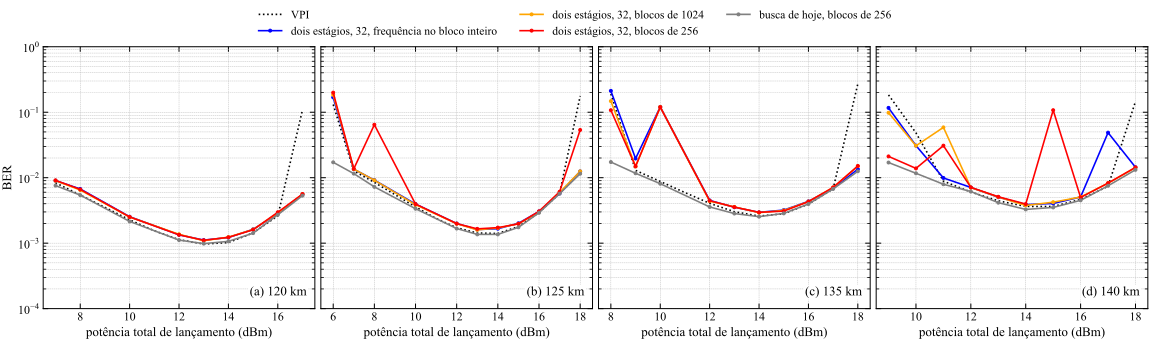

In [16]:
h3 = json.loads((repo / "reference" / "vpi" / "hipoteses" / "h3_frequencia.json").read_text(encoding="utf-8"))["points"]
h3 += [r for r in h1 if r["variant"] in ("base", "por_polarizacao_particionada_22_grossa32", "por_polarizacao_particionada_22")]
searches = {"base": "busca de hoje", "por_polarizacao_particionada_22_grossa32": "dois estágios, 32",
            "por_polarizacao_particionada_22": "dois estágios, 43"}
prefix = {"base": "freq_bloco_", "por_polarizacao_particionada_22_grossa32": "dois_estagios_32_freq_bloco_",
          "por_polarizacao_particionada_22": "dois_estagios_43_freq_bloco_"}
print(f" {'busca de fase':<17} | {'frequência':<17} | bordas | meio  | BER sobre a do VPI, no meio")
for se, se_label in searches.items():
    for block in (None, 1024, 512, 256):
        key = se if block is None else f"{prefix[se]}{block}"
        s = score([r for r in h3 if r["variant"] == key], vpi_known)
        label = "bloco inteiro" if block is None else f"blocos de {block}"
        print(f" {se_label:<17} | {label:<17} | {s['edges']:>6} | {s['middle']:>5} | {s['ber_ratio_median']:.2f}")

shown = {"por_polarizacao_particionada_22_grossa32": ("blue", "dois estágios, 32, frequência no bloco inteiro"),
         "dois_estagios_32_freq_bloco_1024": ("orange", "dois estágios, 32, blocos de 1024"),
         "dois_estagios_32_freq_bloco_256": ("red", "dois estágios, 32, blocos de 256"),
         "freq_bloco_256": ("gray", "busca de hoje, blocos de 256")}
fig, ax = plt.subplots(1, 4, figsize=(16, 4.8), layout="constrained", sharey=True)
for k, (a, L) in enumerate(zip(ax, (120, 125, 135, 140))):
    powers = sorted({r["power_dbm"] for r in h3 if r["length_km"] == L})
    v = sorted((p for p in known[L] if powers[0] <= p["power_dbm"] <= powers[-1]), key=lambda p: p["power_dbm"])
    a.semilogy([p["power_dbm"] for p in v], [p["ber"] for p in v], ":", color="black", lw=1.6)
    for key, (color, _) in shown.items():
        pts = sorted((r for r in h3 if r["variant"] == key and r["length_km"] == L), key=lambda r: r["power_dbm"])
        a.semilogy([r["power_dbm"] for r in pts], [r["ber"] for r in pts], "-", marker=".", ms=6, color=color)
    a.set(xlabel="potência total de lançamento (dBm)", ylim=(1e-4, 1))
    panel_label(a, f"({'abcd'[k]}) {L} km", corner="lower right")
ax[0].set(ylabel="BER")
handles = [(Line2D([], [], ls=":", color="black", lw=1.6), "VPI")]
handles += [(Line2D([], [], color=c, marker=".", ms=6), label) for c, label in shown.values()]
legend_above(fig, [h for h, _ in handles], [t for _, t in handles], ncol=3)
plt.show()

105 polarizações do VPI com a fase perdida e 3 trocas de estado ou mais, 8236 trocas
  período de  256 símbolos:  101.9   (ao acaso: 105 ± 10)
  período de  512 símbolos:  116.6   (ao acaso: 105 ± 10)
  período de 1024 símbolos:   89.4   (ao acaso: 105 ± 10)
  período de 2048 símbolos:  109.6   (ao acaso: 105 ± 10)
  período de 4096 símbolos:  103.2   (ao acaso: 105 ± 10)


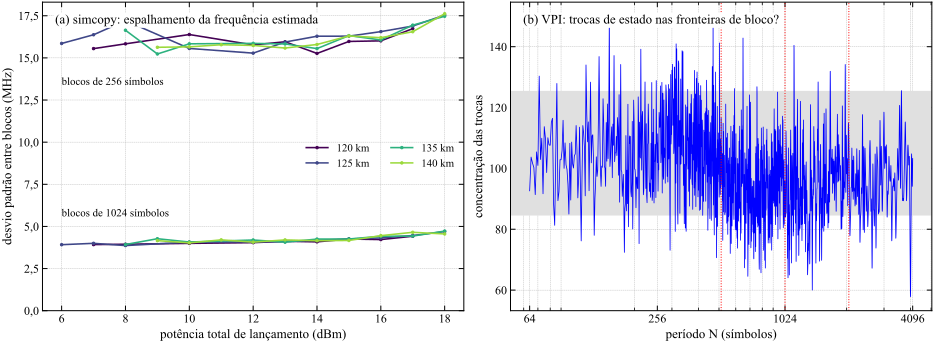

In [17]:
boundaries = json.loads((repo / "reference" / "vpi" / "hipoteses" / "h3_fronteiras_vpi.json").read_text(encoding="utf-8"))
use = [np.array(r["transitions"]) for r in boundaries if len(r["transitions"]) >= 3]
periods = np.arange(64, 4097)
z = np.zeros(periods.size)
for t in use:
    z += np.abs(np.exp(2j * np.pi * t[None, :] / periods[:, None]).sum(axis=1)) ** 2 / t.size
print(f"{len(use)} polarizações do VPI com a fase perdida e 3 trocas de estado ou mais, {sum(t.size for t in use)} trocas")
for N in (256, 512, 1024, 2048, 4096):
    print(f"  período de {N:4d} símbolos: {z[periods == N][0]:6.1f}   (ao acaso: {len(use)} ± {np.sqrt(len(use)):.0f})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for L in (120, 125, 135, 140):
    color = cmap(0.85 * lengths.index(L) / (len(lengths) - 1))
    for block in (1024, 256):
        pts = sorted((r for r in h3 if r["variant"] == f"freq_bloco_{block}" and r["length_km"] == L),
                     key=lambda r: r["power_dbm"])
        ax[0].plot([r["power_dbm"] for r in pts], [r["freq_std_hz"] / 1e6 for r in pts], "-", marker=".", ms=5,
                   color=color, label=f"{L} km" if block == 1024 else None)
ax[0].text(6, 5.6, "blocos de 1024 símbolos", fontsize="small")
ax[0].text(6, 13.4, "blocos de 256 símbolos", fontsize="small")
ax[0].set(xlabel="potência total de lançamento (dBm)", ylabel="desvio padrão entre blocos (MHz)", ylim=(0, None))
ax[0].legend(ncol=2, fontsize="small", loc="center right")
panel_label(ax[0], "(a) simcopy: espalhamento da frequência estimada", corner="upper left")
ax[1].plot(periods, z, color="blue", lw=0.8)
ax[1].axhspan(len(use) - 2 * np.sqrt(len(use)), len(use) + 2 * np.sqrt(len(use)), color="0.88", lw=0)
for N in (512, 1024, 2048):
    ax[1].axvline(N, color="red", ls=":", lw=1)
ax[1].set(xscale="log", xlabel="período N (símbolos)", ylabel="concentração das trocas", xticks=[64, 256, 1024, 4096],
          xticklabels=["64", "256", "1024", "4096"])
panel_label(ax[1], "(b) VPI: trocas de estado nas fronteiras de bloco?", corner="upper left")
plt.show()

A frequência estimada por blocos não muda nada. O espalhamento entre blocos de 1024 símbolos fica em 4,0 MHz até 12 dBm e em 4,5 MHz de 16 dBm para cima (painel a). Ele quase não cresce com a potência, e 4 MHz giram a constelação menos de 1° numa janela de 32 símbolos. Com a busca de hoje o placar continua 0 de 9 nas bordas e 42 de 42 no meio. Com os dois estágios os números ficam a um ponto, no máximo, dos da hipótese 1.

O teste direto nos dados do VPI vai na mesma direção (painel b). As 8236 trocas de estado das 105 polarizações não se concentram em nenhum período. Em 1024 símbolos a concentração dá 89, e o acaso daria 105 ± 10. Em 512 e 2048 dá 117 e 110, também dentro do ruído. Os trechos girados do VPI começam e terminam em qualquer ponto, então ele não reinicia a fase nem a frequência a cada bloco.

A hipótese 3 fica descartada. A ordem da cadeia não foi testada à parte. A diferença é que o simcopy separa as polarizações antes do equalizador e o VPI depois, e essa etapa, em princípio, não mexe na fase da portadora.

## Perto do limiar, a perda de fase é um evento raro

Duas medidas diretas nos dados do VPI mudam a leitura das três hipóteses.

A primeira compara o ruído que chega à decisão. Em cada ponto em que o VPI converge, o erro de cada símbolo é decomposto na direção do ponto ideal (ruído radial, de amplitude) e na perpendicular (ruído tangencial, de fase). Com ruído branco a razão entre as duas variâncias é 1. O ruído de fase não linear a deixa acima de 1, mais no anel de fora. Script: `scripts/experimentos/ruido_radial_tangencial.py`. Resultados em `reference/vpi/hipoteses/ruido_radial_tangencial.json`.

A segunda conta quantas vezes a constelação do VPI entra no estado girado ao longo dos $2^{18}$ símbolos de cada ponto, com as trocas de estado do teste anterior. Para comparar com o simcopy, a contagem vira entradas por bloco de $2^{14}$ símbolos. No eixo horizontal vai a SNR do simcopy no mesmo ponto. Onde o VPI converge ela fica perto da dele (o código abaixo mostra a diferença), e onde o VPI perde a fase a SNR medida nele fica corrompida pelo giro.

34 pontos em que o VPI converge: SNR do simcopy a 0.15 dB da do VPI, no máximo
de 15 dBm para cima, razão tangencial/radial no anel de fora: diferença de 1.9 %, no máximo
os 9 pontos de borda do placar: de 0.03 a 0.19 entrada por bloco de 2^14
  com a taxa do VPI, um bloco de 2^14 perderia a fase, em média, em 0.71 deles
  chance de perder nas 5 bordas de potência baixa: 1.7e-06
14 pontos com SNR do simcopy entre 9.8 e 10.8 dB: o VPI entra de 0.5 a 6.5 vezes por bloco de 2^14, o simcopy não perde a fase em 14 deles


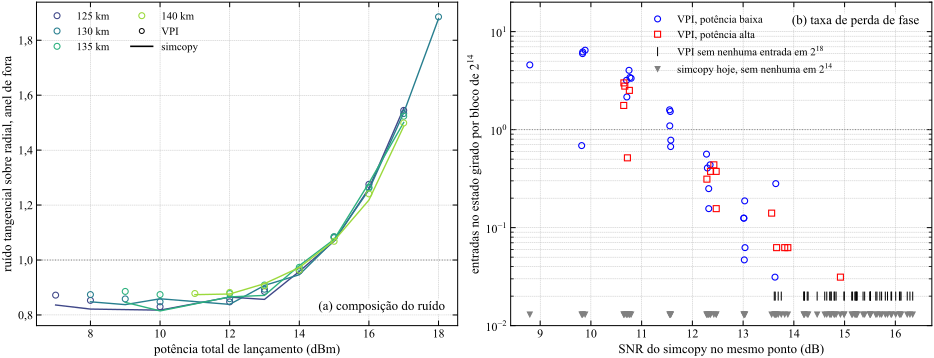

In [18]:
noise = json.loads((repo / "reference" / "vpi" / "hipoteses" / "ruido_radial_tangencial.json").read_text(encoding="utf-8"))["points"]
d_snr = max(abs(p["vpi"]["snr_db"] - p["simcopy"]["snr_db"]) for p in noise)
d_outer = max(abs(p["vpi"]["outer"] / p["simcopy"]["outer"] - 1) for p in noise if p["power_dbm"] >= 15)
print(f"{len(noise)} pontos em que o VPI converge: SNR do simcopy a {d_snr:.2f} dB da do VPI, no máximo")
print(f"de 15 dBm para cima, razão tangencial/radial no anel de fora: diferença de {100 * d_outer:.1f} %, no máximo")

# entradas do VPI no estado girado, por bloco de 2^14 símbolos (média das duas polarizações)
rate = {}
for r in boundaries:
    if r["set"] == "2026_4ch" or (r["set"] == "400gbps_CH2" and r["length_km"] == 120):
        rate.setdefault((r["length_km"], r["power_dbm"]), []).append(max(len(r["transitions"]) / 2, 0.5) / r["n"] * 2**14)
rate = {k: float(np.mean(v)) for k, v in rate.items()}
scored = {(int(r["length_km"]), int(r["power_dbm"])) for r in h1}
edges = sorted(k for k in rate if k in scored)
chance = {k: 1 - np.exp(-rate[k]) for k in edges}
low_edges = [k for k in edges if k[1] < 15]
print(f"os {len(edges)} pontos de borda do placar: de {min(rate[k] for k in edges):.2f} a {max(rate[k] for k in edges):.2f} "
      f"entrada por bloco de 2^14")
print(f"  com a taxa do VPI, um bloco de 2^14 perderia a fase, em média, em {sum(chance.values()):.2f} deles")
print(f"  chance de perder nas {len(low_edges)} bordas de potência baixa: {np.prod([chance[k] for k in low_edges]):.1e}")
far = sorted(k for k in rate if k in ours and 9.5 <= ours[k]["snr_db"] <= 11)
calm = [k for k in far if not lost(ours[k]) and ours[k]["phase_slips"] == 0]
print(f"{len(far)} pontos com SNR do simcopy entre {min(ours[k]['snr_db'] for k in far):.1f} e "
      f"{max(ours[k]['snr_db'] for k in far):.1f} dB: o VPI entra de {min(rate[k] for k in far):.1f} a "
      f"{max(rate[k] for k in far):.1f} vezes por bloco de 2^14, o simcopy não perde a fase em {len(calm)} deles")

fig, ax = plt.subplots(1, 2, figsize=(13, 5.0), layout="constrained")
for L in (125, 130, 135, 140):
    color = cmap(0.85 * lengths.index(L) / (len(lengths) - 1))
    pts = sorted((p for p in noise if p["length_km"] == L), key=lambda p: p["power_dbm"])
    ax[0].plot([p["power_dbm"] for p in pts], [p["simcopy"]["outer"] for p in pts], "-", color=color, lw=1.4)
    ax[0].plot([p["power_dbm"] for p in pts], [p["vpi"]["outer"] for p in pts], "o", mfc="none", ms=6, mew=1.1,
               color=color, label=f"{L} km")
ax[0].axhline(1, color="gray", ls=":", lw=1)
ax[0].plot([], [], "o", mfc="none", color="black", label="VPI")
ax[0].plot([], [], "-", color="black", label="simcopy")
ax[0].set(xlabel="potência total de lançamento (dBm)", ylabel="ruído tangencial sobre radial, anel de fora")
ax[0].legend(ncol=2, fontsize="small", loc="upper left")
panel_label(ax[0], "(a) composição do ruído", corner="lower right")

for high, color, mk, label in ((False, "blue", "o", "VPI, potência baixa"), (True, "red", "s", "VPI, potência alta")):
    ks = [k for k in rate if k in ours and ours[k]["snr_db"] > 8 and (k[1] >= 15) == high]
    ax[1].semilogy([ours[k]["snr_db"] for k in ks], [rate[k] for k in ks], mk, mfc="none", ms=6, mew=1.1, color=color,
                   label=label)
converged = [(L, p["power_dbm"]) for L in lengths for p in known[L] if not lost(p) and (L, p["power_dbm"]) in ours]
ax[1].semilogy([ours[k]["snr_db"] for k in converged], [0.02] * len(converged), "|", ms=9, color="black",
               label="VPI sem nenhuma entrada em $2^{18}$")
none_sim = [k for k, q in ours.items() if q["snr_db"] > 8 and not lost(q) and q["phase_slips"] == 0]
ax[1].semilogy([ours[k]["snr_db"] for k in none_sim], [0.013] * len(none_sim), "v", ms=5, color="gray",
               label="simcopy hoje, sem nenhuma em $2^{14}$")
ax[1].axhline(1, color="gray", ls=":", lw=1)
ax[1].set(xlabel="SNR do simcopy no mesmo ponto (dB)", ylabel="entradas no estado girado por bloco de $2^{14}$",
          ylim=(0.01, 20))
ax[1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(0.3, 0.99))
panel_label(ax[1], "(b) taxa de perda de fase", corner="upper right")
plt.show()

O ruído que chega à busca de fase é o mesmo nos dois simuladores, inclusive em potência alta (painel a). De 15 dBm para cima, a razão entre o ruído tangencial e o radial no anel de fora difere menos de 2 % entre os dois. Em 130 km a 18 dBm ela vale 1,885 no VPI e 1,878 no simcopy. O ruído de fase não linear está reproduzido, e a diferença das bordas não vem do canal.

O painel b mostra duas coisas.

A primeira é que a taxa com que o VPI entra no estado girado depende da SNR, e é a mesma em potência baixa e em potência alta: os pontos azuis e os vermelhos formam uma curva só. A borda de potência alta não precisa de um mecanismo próprio. Ela parecia surgir com SNR mais alta porque, perto do limiar, a perda de fase é rara. O VPI entra no estado girado uma ou duas vezes nos $2^{18}$ símbolos e fica girado por dezenas de milhares de símbolos. Em 125 km a 18 dBm houve uma só entrada, e a constelação ficou girada em 52 % do bloco. Os 9 pontos de borda do placar têm de 0,03 a 0,19 entrada por bloco de $2^{14}$. Com essas taxas, um receptor idêntico ao do VPI, sobre blocos de $2^{14}$ símbolos, perderia a fase em menos de 1 desses 9 pontos, em média.

A segunda é que o receptor de hoje do simcopy entra no estado girado muito menos vezes que o do VPI. Nos pontos com SNR entre 9,8 e 10,8 dB o VPI entra de 0,5 a 6,5 vezes por bloco de $2^{14}$, e o simcopy não perde a fase em nenhum deles.

Isso muda a leitura das hipóteses. Num bloco de $2^{14}$ símbolos, saber se a fase se perdeu ou não só decide longe do limiar. A janela grossa de 21 da hipótese 1 perdeu a fase nas 9 bordas porque entra no estado girado muito mais vezes que o VPI, e por isso também perde no meio. A janela de 32 perdeu a fase nas 5 bordas de potência baixa. Com a taxa do VPI, a chance de perder nas 5 seria de uma em centenas de milhares, então ela também entra mais vezes que o VPI. A busca de hoje entra menos. A leitura dos limiares de SNR na seção "Por que o meio bate" fica corrigida por esta: o limiar não é uma SNR fixa, é uma taxa que cai depressa com a SNR.

O alvo passa a ser outro: um receptor cuja taxa de entradas no estado girado, em função da SNR, siga a curva do VPI. O próximo passo é medir essa taxa no simcopy, para a busca de hoje e para as variantes da hipótese 1. Longe do limiar um bloco de $2^{14}$ símbolos basta, e perto dele são precisos $2^{18}$, como no VPI.

## Hipótese 4: uma busca de fase que não distingue 0° de 45°

Para medir a taxa de perda de fase do simcopy foi preciso um detector melhor. Ele segue, em cada polarização, a fase local contra os símbolos conhecidos (soma de $y\,a^*$ numa janela de 64), em passos de 45°. Conta as trocas de estado que duram 256 símbolos e separa o tempo errado em dois tipos: em múltiplos ímpares de 45° (o estado girado) e em saltos de 90° ou 180°. O mesmo detector roda no VPI (`scripts/experimentos/fronteiras_vpi.py --estados`) e no simcopy.

Ele mostrou três coisas sobre o VPI. A fase caminha ao acaso em passos de 45° por todos os estados: nos pontos perdidos, 62 % do tempo errado fica em 45° e o resto em saltos de 90° e 180°. As duas polarizações trocam de estado juntas, então a fase é estimada em conjunto, apesar do `JointEstimation = No`, que aparece igual nos seis blocos de DSP. E no estado de 45° a constelação é limpa: em 125 km a 18 dBm a SNR com a fase corrigida pelos símbolos conhecidos é 13,92 dB nos trechos girados e 13,86 dB nos alinhados.

Ele também mostrou que as variantes por polarização da hipótese 1 falham de outro jeito: saltam 90° e quase não param em 45° (a correção está na leitura da hipótese 1).

O modelo testado aqui é um estimador que não distingue 0° de 45°. A fase é a mesma nas duas polarizações (a diferença entre elas sai da quarta potência cruzada, $\sum y_1^4\,(y_0^4)^*$). O estágio grosso é a quarta potência dos anéis de dentro e de fora, desdobrada com período de 45° em vez de 90°: um salto de 45° causado pelo ruído não é desfeito, e nada puxa a fase de volta. O estágio fino é a busca na grade do 16QAM, ±22,5° em torno da grossa, com a janela de 43. O equalizador é o de hoje, calculado uma vez por sinal, porque no VPI o equalizador vem antes da busca de fase e não depende dela.

Os sinais são os 99 pontos do simcopy de 120 a 140 km, de 0 a 20 dBm, com $2^{14}$ símbolos (48 deles simulados para esta seção, longe do limiar). O eixo de SNR é a SNR com a fase corrigida pelos símbolos conhecidos, medida uma vez por ponto, e vale para o VPI no mesmo ponto. Script: `scripts/experimentos/busca_fase_vpi.py --fixed-equalizer`. Resultados em `reference/vpi/hipoteses/h4_estados.json` e `estados_fase_vpi.json`.

VPI: trocas de estado de uma polarização com uma troca da outra a menos de 300 símbolos: 5688 de 6199
VPI: tempo errado em 45°, nos pontos perdidos: 62 %

 variante                                                           | trocas sobre | em 45° | perde a mais | BER sobre a do | SNR com fase conhecida
                                                                    | as do VPI    |        | no meio      | VPI, no meio   | nos perdidos (dB)
 busca de hoje                                                      |         0.20 |    3 % |     0 de 42 |           0.97 | +0.00
 hipótese 1: dois estágios por polarização, janela grossa de 32     |         1.16 |    8 % |     5 de 42 |           1.11 | -0.68
 por polarização, quarta potência em 45° e busca fina               |         0.82 |   60 % |     2 de 42 |           1.14 | -1.41
 conjunta, só a quarta potência em 45°, janela de 43                |         0.52 |   63 % |     0 de 42 |           1.08 | -0.01
 conjunta, quarta potência e

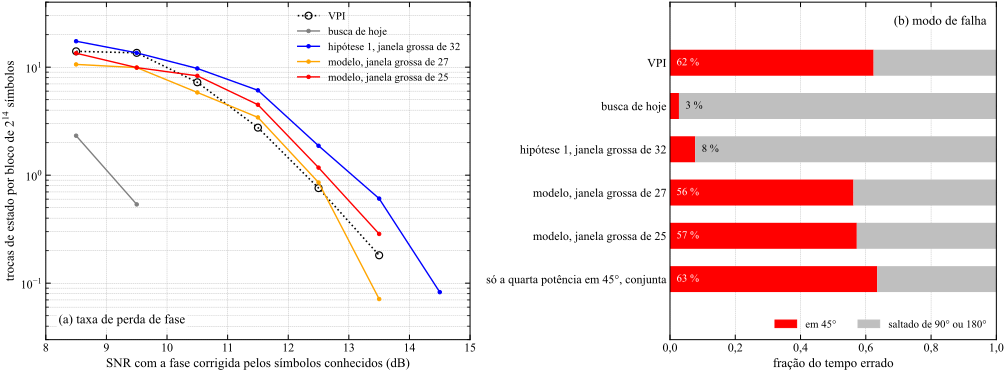

In [19]:
h4 = json.loads((repo / "reference" / "vpi" / "hipoteses" / "h4_estados.json").read_text(encoding="utf-8"))["points"]
vpi_states = json.loads((repo / "reference" / "vpi" / "hipoteses" / "estados_fase_vpi.json").read_text(encoding="utf-8"))
catalog_known = {(p["length_km"], p["power_dbm"]): p for L in lengths for p in known[L]}

def wrong(q):
    return q["f45"] + q["fsl"] > 0.02 or q["ber"] > 0.1

vst = {}
for r in vpi_states:
    vst.setdefault((r["length_km"], r["power_dbm"]), []).append(r)
pairs = [(v[0], v[1]) for v in vst.values() if len(v) == 2]
near = sum(np.min(np.abs(np.array(b["changes"]) - c)) < 300 for a, b in pairs if a["changes"] and b["changes"] for c in a["changes"])
total = sum(len(a["changes"]) for a, b in pairs if a["changes"] and b["changes"])
vst = {k: {"rate": np.mean([len(r["changes"]) / r["n"] * 2**14 for r in v]), "f45": np.mean([r["frac_45"] for r in v]),
           "fsl": np.mean([r["frac_slipped"] for r in v]), "ber": catalog_known[k]["ber"]} for k, v in vst.items()}
sim = {}
for r in h4:
    sim.setdefault(r["variant"], {})[(int(r["length_km"]), int(r["power_dbm"]))] = {
        "rate": r["changes"] / r["n_symbols"] * 2**14, "f45": r["frac_45"], "fsl": r["frac_slipped"], "ber": r["ber"],
        "snr": r["snr_known_phase_db"]}
snr_of = {k: q["snr"] for k, q in sim["base"].items()}
points = sorted(k for k in snr_of if k in vst)

def share45(d):
    lost_k = [k for k in points if wrong(d[k])]
    a, b = sum(d[k]["f45"] for k in lost_k), sum(d[k]["fsl"] for k in lost_k)
    return a / (a + b) if a + b else 0.0

print(f"VPI: trocas de estado de uma polarização com uma troca da outra a menos de 300 símbolos: {near} de {total}")
print(f"VPI: tempo errado em 45°, nos pontos perdidos: {100 * share45(vst):.0f} %\n")
variants = {
    "base": "busca de hoje",
    "por_polarizacao_particionada_22_grossa32": "hipótese 1: dois estágios por polarização, janela grossa de 32",
    "periodo45_grossa43_fina22.5": "por polarização, quarta potência em 45° e busca fina",
    "conjunta45_quarta43_aneis": "conjunta, só a quarta potência em 45°, janela de 43",
    "conjunta45_grossa32_fina22.5": "conjunta, quarta potência em 45° e busca fina, janela grossa de 32",
    "conjunta45_grossa27_fina22.5": "   o mesmo, janela grossa de 27",
    "conjunta45_grossa25_fina22.5": "   o mesmo, janela grossa de 25",
    "conjunta45_grossa21_fina22.5": "   o mesmo, janela grossa de 21",
}
base_snr = snr_of
print(f" {'variante':<66} | trocas sobre | em 45° | perde a mais | BER sobre a do | SNR com fase conhecida")
print(f" {'':<66} | as do VPI    |        | no meio      | VPI, no meio   | nos perdidos (dB)")
for key, label in variants.items():
    d = sim[key]
    mid = [k for k in points if not wrong(vst[k])]
    ratio = np.median([d[k]["ber"] / vst[k]["ber"] for k in mid if not wrong(d[k])])
    lost_k = [k for k in points if d[k]["f45"] + d[k]["fsl"] > 0.1]
    drop = np.median([d[k]["snr"] - base_snr[k] for k in lost_k]) if lost_k else float("nan")
    rate = sum(d[k]["rate"] for k in points) / sum(vst[k]["rate"] for k in points)
    print(f" {label:<66} | {rate:12.2f} | {100 * share45(d):4.0f} % | {sum(wrong(d[k]) for k in mid):5d} de {len(mid)} | "
          f"{ratio:14.2f} | {drop:+.2f}")

edges = np.arange(8.0, 16.01, 1.0)
def binned(d):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        ks = [k for k in points if lo <= snr_of[k] < hi]
        out.append(np.mean([d[k]["rate"] for k in ks]) if ks else np.nan)
    return np.array(out)

centers = edges[:-1] + 0.5
shown = {"base": ("gray", "busca de hoje"), "por_polarizacao_particionada_22_grossa32": ("blue", "hipótese 1, janela grossa de 32"),
         "conjunta45_grossa27_fina22.5": ("orange", "modelo, janela grossa de 27"),
         "conjunta45_grossa25_fina22.5": ("red", "modelo, janela grossa de 25")}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]})
y = binned(vst)
ax[0].semilogy(centers[y > 0.01], y[y > 0.01], ":", marker="o", mfc="none", ms=7, mew=1.2, color="black", lw=1.6, label="VPI")
for key, (color, label) in shown.items():
    y = binned(sim[key])
    ax[0].semilogy(centers[y > 0.01], y[y > 0.01], "-", marker=".", ms=7, color=color, lw=1.4, label=label)
ax[0].set(xlabel="SNR com a fase corrigida pelos símbolos conhecidos (dB)",
          ylabel="trocas de estado por bloco de $2^{14}$ símbolos", ylim=(0.03, 40), xlim=(8, 15))
ax[0].legend(fontsize="small", loc="upper right")
panel_label(ax[0], "(a) taxa de perda de fase", corner="lower left")

bars = [("VPI", vst)] + [(label, sim[key]) for key, (_, label) in shown.items()] + \
       [("só a quarta potência em 45°, conjunta", sim["conjunta45_quarta43_aneis"])]
for i, (label, d) in enumerate(bars):
    s = share45(d)
    ax[1].barh(i, s, color="red", height=0.6)
    ax[1].barh(i, 1 - s, left=s, color="0.75", height=0.6)
    ax[1].text(0.02 if s > 0.1 else s + 0.02, i, f"{100 * s:.0f} %", va="center",
                color="white" if s > 0.1 else "black", fontsize="small")
ax[1].set(yticks=range(len(bars)), yticklabels=[b[0] for b in bars], xlim=(0, 1), xlabel="fração do tempo errado",
          ylim=(len(bars) + 0.4, -1.4))     # uma faixa livre em cima (rótulo) e embaixo (legenda)
ax[1].legend([plt.Rectangle((0, 0), 1, 1, color="red"), plt.Rectangle((0, 0), 1, 1, color="0.75")],
             ["em 45°", "saltado de 90° ou 180°"], fontsize="small", loc="lower right", ncol=2)
panel_label(ax[1], "(b) modo de falha", corner="upper right")
plt.show()

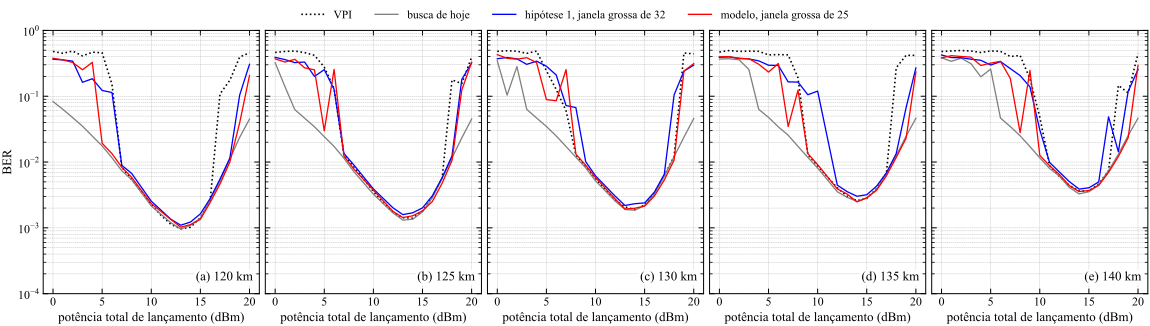

In [20]:
ber_shown = {"base": ("gray", "busca de hoje"), "por_polarizacao_particionada_22_grossa32": ("blue", "hipótese 1, janela grossa de 32"),
             "conjunta45_grossa25_fina22.5": ("red", "modelo, janela grossa de 25")}
fig, ax = plt.subplots(1, len(lengths), figsize=(16, 4.6), layout="constrained", sharey=True)
for k, (a, L) in enumerate(zip(ax, lengths)):
    v = sorted(known[L], key=lambda p: p["power_dbm"])
    a.semilogy([p["power_dbm"] for p in v], [p["ber"] for p in v], ":", color="black", lw=1.6)
    for key, (color, _) in ber_shown.items():
        pts = sorted((kk[1], q["ber"]) for kk, q in sim[key].items() if kk[0] == L)
        a.semilogy([x for x, _ in pts], [b for _, b in pts], "-", color=color, lw=1.3)
    a.set(xlabel="potência total de lançamento (dBm)", ylim=(1e-4, 1))
    panel_label(a, f"({'abcde'[k]}) {L} km", corner="lower right")
ax[0].set(ylabel="BER")
legend_above(fig, [Line2D([], [], ls=":", color="black", lw=1.6)] + [Line2D([], [], color=c, lw=1.3) for c, _ in ber_shown.values()],
             ["VPI"] + [label for _, label in ber_shown.values()], ncol=4)
plt.show()

O modelo reproduz o VPI em três das quatro assinaturas.

A taxa de trocas acompanha a do VPI de 8 a 13 dB de SNR (painel a). Com a janela grossa de 25 o total fica em 0,90 vez o do VPI, e com a de 27 em 0,76. A de 21 já troca de 3 a 5 vezes mais que o VPI perto do limiar, e a de 32 bem menos. Na potência alta, com a janela de 27, a taxa vai a 6,3 e 0,64 trocas por bloco de $2^{14}$ em 10 e 12 dB, contra 5,4 e 0,72 no VPI. A borda de potência alta sai da mesma regra que a baixa.

O modo de falha é o do VPI (painel b): 56 a 57 % do tempo errado fica em 45°, contra 62 % no VPI, e o resto em saltos de 90° e 180°. As variantes da hipótese 1 ficam em até 10 %, e a busca de hoje quase não perde a fase.

No meio a BER é a do VPI, de 0,98 a 1,00 vez, sem nenhum ponto perdido a mais. Nas curvas de BER, a do modelo tem as duas quedas do VPI, a de potência baixa e a de potência alta. Perto do limiar cada ponto depende de um bloco de $2^{14}$ símbolos, e a perda de fase ali é um evento raro, então ponto a ponto as curvas não coincidem.

A quarta assinatura não sai. No estado de 45° do VPI a constelação é limpa, e no modelo a busca fina treme entre as pontas do intervalo: nos pontos perdidos, a SNR com a fase corrigida pelos símbolos conhecidos cai 1,4 a 1,6 dB. Só com a quarta potência, sem busca fina, o estado de 45° fica limpo, mas a BER no meio sobe para 1,08 vez a do VPI e a taxa cai à metade. A parte fina da busca do VPI deve ser outra: tão precisa quanto a busca na grade do 16QAM, e sem distinguir uma constelação girada de 45°. A grade de `256QAM_constellation.txt` (`Format = ReadFromFile`) é a candidata natural, e o arquivo não está com a gente.

Ressalvas. As taxas vêm de um bloco de $2^{14}$ símbolos por ponto, e perto do limiar cada ponto tem poucas trocas, por isso a comparação é por faixa de SNR. O equalizador é o de hoje, calculado uma vez por sinal. E o modelo é uma reconstrução a partir do comportamento: ele reproduz o que o VPI faz, mas não prova que o VPI faça assim.

Próximos passos: pedir ao grupo o arquivo `256QAM_constellation.txt` e o trecho do manual do VPI sobre o `BlindPhaseSearch`, testar uma busca fina que não distinga 0° de 45°, e simular alguns pontos perto do limiar com $2^{18}$ símbolos para medir as taxas raras.